<a href="https://colab.research.google.com/github/Papawadee-Mohdee/sc663402-pandas-review/blob/main/%E0%B8%9B%E0%B8%A0%E0%B8%B2%E0%B8%A7%E0%B8%94%E0%B8%B5_Pandas_Review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# นางสาวปภาวดี เหมาะดี รหัส 673020256-6


# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-thai-tlwg is already the newest version (1:0.7.3-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!


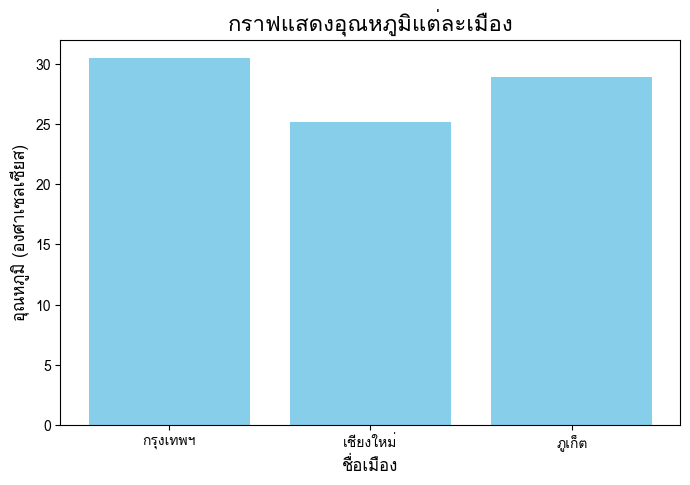

In [1]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [2]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

### เซลล์ 1.1 — เข้าถึงค่าเดี่ยว vs เข้าถึงหลายค่าใน `Series`

- `s["a"]` (label-based, เหมือน `.loc`) และ `s.iloc[0]` (position-based) — ทั้งคู่คืนค่า **scalar** (เลข `int` ธรรมดา ไม่มี index ติดมา) เพราะส่ง key/ตำแหน่งเดี่ยวเข้าไป ในเคสนี้ label `"a"` บังเอิญอยู่ตำแหน่ง `0` พอดี ผลเลยตรงกันคือ `10` แต่ถ้า index ถูกสลับลำดับ ค่าจะต่างกันได้ทันที
- `s[["a", "c"]]` — ส่ง `list` ของ label เข้าไป ผลลัพธ์จึงเป็น **`Series`** (ไม่ใช่ scalar) ที่มีแค่ 2 สมาชิกพร้อม index เดิม

**ใช้เมื่อไร:** ต้องการค่าเดียวไปคำนวณต่อ → ใช้ `s["a"]` หรือ `s.iloc[0]`; ใช้ `.iloc` เมื่อสนใจตำแหน่งแน่นอน ส่วน label indexing เหมาะเมื่อสนใจ "ความหมาย" ของ label มากกว่าลำดับแถว (โค้ดจะทนทานกว่าแม้ข้อมูลถูกเรียงใหม่); ต้องการหลายค่าพร้อม index → ใช้ `list` of labels เช่น `s[["a", "c"]]`

---

In [3]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


### เซลล์ 1.2 — bracket เดี่ยว vs bracket ซ้อน (`list`) ใน `DataFrame`

- `df["city"]` → **`Series`** 1 มิติ, `shape` เป็น `(2075,)`
- `df[["city"]]` → **`DataFrame`** 2 มิติ, `shape` เป็น `(2075, 1)` แม้จะมีคอลัมป์เดียว

หลักการทั่วไป: ส่ง key เดี่ยวเข้า `[]` → มิติลดลง (`Series`), ส่ง `list` เข้า `[]` → คงเป็น `DataFrame` เสมอไม่ว่าจะมีกี่คอลัมป์

**ใช้เมื่อไร:** ต้องการ vector เดียวไป plot เส้น/คำนวณ `.mean()` เดี่ยว ๆ → `df["city"]`; ต้องการคงโครงสร้างตาราง เผื่อเพิ่มคอลัมป์, ส่งต่อฟังก์ชันที่รับ `DataFrame`, หรือ merge/join → `df[["city"]]`

---

In [4]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)  # อัรรี้เฉพาะคอลัมป์
print(type(df[["city"]]), df[["city"]].shape) # ต้องการ data ใหญ่ หลายคอลัมป์ อันนี้สะดวกกว่า

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


### เซลล์ 1.3 — `.loc` (inclusive) vs `.iloc` (exclusive)

- `df.loc[0:3]` → ตัดตาม **label** ของ index และ **รวมจุดสิ้นสุด** → ได้แถว `0, 1, 2, 3` รวม 4 แถว
- `df.iloc[0:3]` → ตัดตาม **ตำแหน่ง** แบบ Python slicing ปกติ **ไม่รวมจุดสิ้นสุด** → ได้แถว `0, 1, 2` รวม 3 แถว

จุดนี้เป็นกับดักที่มือใหม่พลาดบ่อยที่สุดจุดหนึ่งของ `pandas`

**ใช้เมื่อไร:** ถ้า index เป็นตัวเลขเรียงต่อกันและต้องการพฤติกรรม slicing แบบ Python มาตรฐาน → ใช้ `.iloc`; ถ้า index มีความหมาย (เช่นวันที่) และต้องการเลือกช่วงแบบรวมทั้งสองปลาย เช่น `df.loc["2024-01-01":"2024-01-31"]` → ใช้ `.loc`

---

In [5]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


###เซลล์ 1.4 — `count()` vs `size()` ใน `groupby`

- `df.groupby("city")["temperature_c"].count()` → นับเฉพาะค่าที่ **ไม่ใช่ `NaN`** ในคอลัมป์นั้น → `Beijing` ได้ `89` แปลว่ามีข้อมูลขาดหาย 1 แถว
- `df.groupby("city").size()` → นับ **จำนวนแถวทั้งหมด** ในกลุ่ม ไม่สนใจ `NaN` → `Beijing` ได้ `90` (จำนวนจริง)

**ใช้เมื่อไร:** ต้องการเช็คว่าคอลัมป์ที่จะเอาไปคำนวณสถิติมีข้อมูลสมบูรณ์กี่ค่า → `.count()`; ต้องการขนาดกลุ่มจริง → `.size()`; เทคนิคที่ใช้บ่อย: เทียบ `count()` กับ `size()` ของคอลัมป์เดียวกัน ถ้าตัวเลขไม่เท่ากันคือมี missing data ในกลุ่มนั้น

---

In [6]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


### เซลล์ 1.5 — หลักการเดียวกับเซลล์ 1.2 แต่ทำหลัง `groupby`

- `df.groupby("city")["temperature_c"].mean()` → **`Series`** (มีแค่ `.name`)
- `df.groupby("city")[["temperature_c"]].mean()` → **`DataFrame`** (มี column header ชัดเจน)

ค่าตัวเลขเหมือนกันทุกประการ ต่างแค่ "รูปร่าง container" — เป็นกฎเดียวกับเซลล์ 1.2

**ใช้เมื่อไร:** เอาไป plot/รวมกับ `Series` อื่นแบบ 1 มิติ → bracket เดี่ยว; ต้องการทำ `.mean()` หลายคอลัมป์พร้อมกัน หรืออยาก `.reset_index()`/merge ต่อง่าย → bracket ซ้อน `list`

---

In [7]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


### เซลล์ 1.6 — index alignment (`pandas`) vs positional (`numpy`)

- `a` และ `b` มีลำดับ index ต่างกัน (`"x", "y", "z"` กับ `"z", "y", "x"`)
- `a + b` → `pandas` **จับคู่ตาม label ของ index ก่อน** แล้วค่อยบวก: `x = 1+30 = 31`, `y = 2+20 = 22`, `z = 3+10 = 13`
- `a.to_numpy() + b.to_numpy()` → แปลงเป็น `array` ก่อน index หายไป บวกแบบ **ตามตำแหน่ง** ล้วน ๆ: `[1+10, 2+20, 3+30] = [11, 22, 33]`

**ใช้เมื่อไร:** ข้อมูลสองชุดมาจากคนละแหล่งและอยากให้จับคู่ตามความหมายของ label อัตโนมัติ (เช่น รวมยอดขายตาม ID ที่เรียงไม่ตรงกัน) → ปล่อยให้ `pandas` align ตามปกติ นี่คือจุดแข็งสำคัญของ `pandas` เทียบ `numpy`; มั่นใจว่าลำดับตรงกันอยู่แล้วและต้องการความเร็ว → ค่อยใช้ `.to_numpy()` แต่ต้องระวังเพราะถ้าลำดับไม่ตรง ผลจะผิดโดยไม่มี error เตือนเลย

---

In [8]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [9]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [10]:
# คำตอบข้อ 2.1
# ต้องมีการ groupby และ pivot_table
# หมายเหตุ: ข้อนี้ใช้ df ตามที่โหลดมา (ยังไม่ทำความสะอาด) เพราะการตรวจคุณภาพข้อมูลจะทำในข้อ 4 และข้อ 8

# สร้าง Series rain_by_city ด้วย pivot_table โดยให้ index เป็นชื่อเมือง
rain_by_city = (df.pivot_table(index="city", values="rainfall_mm", aggfunc="sum")["rainfall_mm"]
                  .rename("rain_by_city"))

# ตรวจสอบว่าผลจาก pivot_table ตรงกับ groupby
rain_check = df.groupby("city")["rainfall_mm"].sum()
print("pivot_table ตรงกับ groupby:", np.allclose(rain_by_city.sort_index(), rain_check.sort_index()))

# 1) เมืองที่ปริมาณฝนรวมสูงสุด 3 อันดับแรก
print("\n1) เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก")
print(rain_by_city.nlargest(3))

# 2) สัดส่วนปริมาณฝนของแต่ละเมือง (ร้อยละ ทศนิยม 2 ตำแหน่ง)
rain_share_pct = (rain_by_city / rain_by_city.sum() * 100).round(2)
print("\n2) สัดส่วนปริมาณฝนของแต่ละเมือง (%)")
print(rain_share_pct.sort_values(ascending=False))

# 3) จำนวนเมืองที่ปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง
mean_rain = rain_by_city.mean()
n_above = (rain_by_city > mean_rain).sum()
print(f"\n3) ค่าเฉลี่ยของทุกเมือง = {mean_rain:.2f} mm -> มี {n_above} เมืองที่สูงกว่าค่าเฉลี่ย")

pivot_table ตรงกับ groupby: True

1) เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
city
Singapore    870.4
Bangkok      685.6
Lagos        652.8
Name: rain_by_city, dtype: float64

2) สัดส่วนปริมาณฝนของแต่ละเมือง (%)
city
Singapore       10.43
Bangkok          8.21
Lagos            7.82
Mumbai           5.84
Chiang Mai       5.22
Sao Paulo        5.07
Nairobi          4.74
Tokyo            4.61
Auckland         4.22
Paris            3.99
Sydney           3.97
Toronto          3.81
New York         3.78
Mexico City      3.66
Buenos Aires     3.65
London           3.27
Berlin           3.21
Beijing          3.00
Moscow           2.96
Cape Town        2.87
Lima             2.16
Los Angeles      2.03
Cairo            1.47
Name: rain_by_city, dtype: float64

3) ค่าเฉลี่ยของทุกเมือง = 362.97 mm -> มี 8 เมืองที่สูงกว่าค่าเฉลี่ย


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [11]:
# คำตอบข้อ 2.2
# หมายเหตุ: country ในข้อมูลดิบมีทั้ง "Japan" และ "JAPAN" จึงใช้ค่าที่พบบ่อยที่สุด (mode) ของเมืองนั้น
#           (วนตามกลุ่มเมืองเพียง 23 กลุ่ม ไม่ได้วนทีละแถว)
city_profile = (
    df.groupby("city")
      .agg(
          country=("country", lambda s: s.mode().iat[0]),
          region=("region", "first"),
          n_records=("record_id", "count"),
          avg_temp=("temperature_c", "mean"),
          total_rain=("rainfall_mm", "sum"),
      )
      .round({"avg_temp": 2, "total_rain": 2})
      .reset_index()
)

print(city_profile.shape)   # หนึ่งแถวต่อหนึ่งเมือง
city_profile

(23, 6)


,city,country,region,n_records,avg_temp,total_rain
0,Auckland,New Zealand,Oceania,90,17.80,351.9
1,Bangkok,Thailand,Asia,91,32.45,685.6
2,Beijing,China,Asia,90,15.60,250.1
3,Berlin,Germany,Europe,90,12.38,268.4
4,Buenos Aires,Argentina,South America,90,19.17,305.1
5,Cairo,Egypt,Africa,91,26.09,123.0
6,Cape Town,South Africa,Africa,90,30.16,239.3
7,Chiang Mai,Thailand,Asia,91,29.68,435.6
8,Lagos,Nigeria,Africa,90,29.49,652.8
9,Lima,Peru,South America,90,21.49,180.3


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [12]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [13]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [14]:
# คำตอบข้อ 3.1
df_opt = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"],  # 1) อ่านเฉพาะคอลัมน์ที่ต้องการ
    parse_dates=["date"],                                                                # 2) date เป็น datetime
    na_values=[999, -999],                                                               # 3) 999 และ -999 เป็นค่าว่าง
    dtype={"city": "category", "region": "category"},                                    # 4) ชนิด category
    index_col="city",                                                                    # 5) city เป็น index
)

print(df_opt.dtypes)
print()
df_opt.info()

date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 2075 entries, New York to Paris
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   region         2075 non-null   category      
 2   temperature_c  2052 non-null   float64       
 3   humidity_pct   1993 non-null   float64       
 4   rainfall_mm    2013 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 69.8 KB


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [15]:
# คำตอบข้อ 3.2
raw_full = pd.read_csv(BASE + "world_weather_sample.csv")      # นำเข้าตามปกติ

total_raw = raw_full.memory_usage(deep=True).sum()
total_opt = df_opt.memory_usage(deep=True).sum()
print(f"ตารางปกติ  : {total_raw/1024:,.1f} KB")
print(f"ตารางข้อ 3.1: {total_opt/1024:,.1f} KB")
print(f"หน่วยความจำลดลง {(1 - total_opt/total_raw)*100:.1f}%")

# เปรียบเทียบรายคอลัมน์ (city ในตารางข้อ 3.1 ย้ายไปเป็น index จึงนำ memory ของ index มาเทียบแทน)
mem_raw = raw_full.memory_usage(deep=True, index=False)
mem_opt = df_opt.memory_usage(deep=True, index=False)
mem_opt["city"] = df_opt.index.memory_usage(deep=True)

cmp = pd.DataFrame({"ปกติ (bytes)": mem_raw, "ข้อ 3.1 (bytes)": mem_opt}).fillna(0)   # คอลัมน์ที่ไม่ได้อ่านเป็น 0
cmp["ประหยัดได้ (bytes)"] = cmp["ปกติ (bytes)"] - cmp["ข้อ 3.1 (bytes)"]
cmp["สัดส่วนที่ลดลงจากทั้งหมด (%)"] = (cmp["ประหยัดได้ (bytes)"] / total_raw * 100).round(1)
cmp = cmp.sort_values("ประหยัดได้ (bytes)", ascending=False)
print()
print(cmp)

# แยกส่วนที่ประหยัดได้: (1) จากการไม่อ่านคอลัมน์ที่ไม่ใช้ (usecols)  (2) จากการเปลี่ยนชนิดข้อมูลของคอลัมน์ที่อ่านเข้ามา
read_cols = df_opt.columns.tolist() + [df_opt.index.name]
saved_dropped = cmp.drop(index=read_cols)["ประหยัดได้ (bytes)"].sum()
saved_dtype = cmp.loc[read_cols, "ประหยัดได้ (bytes)"].sum()
print(f"\nประหยัดจากการไม่อ่านคอลัมน์ที่ไม่ใช้ (usecols): {saved_dropped / total_raw * 100:.1f}% ของทั้งหมด")
print(f"ประหยัดจากการกำหนดชนิดข้อมูล (category / datetime): {saved_dtype / total_raw * 100:.1f}% ของทั้งหมด")

top = cmp.loc[read_cols, "ประหยัดได้ (bytes)"].idxmax()          # คอลัมน์ที่ถูกอ่านเข้ามาและประหยัดได้มากที่สุด
dtype_after = df_opt.index.dtype if top == df_opt.index.name else df_opt[top].dtype
print(f"คอลัมน์ที่ช่วยลดหน่วยความจำมากที่สุด (ในคอลัมน์ที่อ่านเข้ามา): `{top}` ชนิดเดิม {raw_full[top].dtype} -> {dtype_after}")

ตารางปกติ  : 558.2 KB
ตารางข้อ 3.1: 71.2 KB
หน่วยความจำลดลง 87.2%

                ปกติ (bytes)  ข้อ 3.1 (bytes)  ประหยัดได้ (bytes)  \
region                117631           2590.0            115041.0   
country               114937              0.0            114937.0   
city                  116920           3927.0            112993.0   
date                  122425          16600.0            105825.0   
record_id              16600              0.0             16600.0   
pressure_hpa           16600              0.0             16600.0   
wind_speed_kmh         16600              0.0             16600.0   
humidity_pct           16600          16600.0                 0.0   
rainfall_mm            16600          16600.0                 0.0   
temperature_c          16600          16600.0                 0.0   

                สัดส่วนที่ลดลงจากทั้งหมด (%)  
region                                  20.1  
country                                 20.1  
city                            

**คำตอบข้อ 3.2 (อธิบาย):**

หน่วยความจำลดลงจากสองส่วน ส่วนแรกคือการเปลี่ยนชนิดข้อมูลของคอลัมน์ที่อ่านเข้ามา และส่วนที่สองคือ `usecols` ที่ไม่อ่านคอลัมน์ที่ไม่ใช้ (`country`, `record_id`, `wind_speed_kmh`, `pressure_hpa`) ตามตัวเลขที่โปรแกรมพิมพ์ไว้

ในส่วนของการเปลี่ยนชนิดข้อมูล **คอลัมน์ที่ช่วยลดมากที่สุดคือคอลัมน์ข้อความ** (`city`, `region` หรือ `date` ตามที่โปรแกรมด้านบนพิมพ์ไว้ ซึ่งขนาดใกล้เคียงกันมาก) เพราะเมื่อ `read_csv` อ่านตามปกติ คอลัมน์ข้อความจะเก็บสตริงของทุกแถวแยกกัน ทั้งที่ค่าซ้ำกันเป็นส่วนใหญ่ (มีเพียง 23 เมืองและ 6 ภูมิภาค แต่มี 2,075 แถว) การกำหนดเป็น `category` จะเก็บชื่อที่ไม่ซ้ำเพียงครั้งเดียว แล้วใช้รหัสจำนวนเต็มขนาดเล็กแทนในแต่ละแถว ส่วน `date` เมื่อแปลงเป็น `datetime64` จะใช้เพียง 8 ไบต์ต่อค่า แทนสตริงความยาว 10 ตัวอักษร ส่วนคอลัมน์ตัวเลข (`temperature_c`, `humidity_pct`, `rainfall_mm`) ยังเป็น `float64` เหมือนเดิมจึงไม่มีผลต่อการลดลง

### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [16]:
# คำตอบข้อ 3.3
# หมายเหตุ: ใช้ for วนตาม "ก้อน" (chunk) เท่านั้น ไม่ได้วนทีละแถว เพราะ chunksize ต้องอ่านทีละก้อนตามธรรมชาติ
#           ภายในแต่ละก้อนคำนวณแบบ vectorized และไม่ใช้ pd.concat
path = BASE + "world_weather_sample.csv"

raw_max, raw_min = -np.inf, np.inf       # ค่าสูงสุด/ต่ำสุดจากข้อมูลดิบ
val_max, val_min = -np.inf, np.inf       # ค่าสูงสุด/ต่ำสุด เฉพาะค่าที่เป็นไปได้ทางกายภาพ (-60 ถึง 60)
acc = None                               # สะสม sum และ count ของแต่ละเมือง
wrong_sum, wrong_n = None, None          # ใช้สาธิตวิธีที่ผิด (เฉลี่ยของค่าเฉลี่ยรายก้อน)

for chunk in pd.read_csv(path, usecols=["city", "temperature_c"], chunksize=500):
    t = chunk["temperature_c"]
    raw_max, raw_min = max(raw_max, t.max()), min(raw_min, t.min())

    t_valid = t.where(t.between(-60, 60))                    # ค่านอกช่วงเป็นค่าว่าง
    val_max, val_min = max(val_max, t_valid.max()), min(val_min, t_valid.min())

    part = t_valid.groupby(chunk["city"]).agg(["sum", "count"])   # สะสมค่าที่ใช้คำนวณค่าเฉลี่ยได้ถูกต้อง
    acc = part if acc is None else acc.add(part, fill_value=0)

    m = t_valid.groupby(chunk["city"]).mean()                 # วิธีที่ผิด: เก็บค่าเฉลี่ยของแต่ละก้อน
    wrong_sum = m if wrong_sum is None else wrong_sum.add(m, fill_value=0)
    wrong_n = m.notna().astype(int) if wrong_n is None else wrong_n.add(m.notna().astype(int), fill_value=0)

print(f"1) ข้อมูลดิบ: สูงสุด = {raw_max}, ต่ำสุด = {raw_min}")
print(f"   เฉพาะค่าที่เป็นไปได้ (-60 ถึง 60): สูงสุด = {val_max}, ต่ำสุด = {val_min}")

mean_by_city = (acc["sum"] / acc["count"]).rename("avg_temp")
print("\n2) อุณหภูมิเฉลี่ยรายเมือง (สะสม sum และ count)")
print(mean_by_city.round(2))

# ตรวจสอบกับการโหลดทั้งไฟล์ (df ถูกโหลดไว้แล้วในส่วนที่ 0 ใช้เพื่อตรวจคำตอบเท่านั้น)
expected = df["temperature_c"].where(df["temperature_c"].between(-60, 60)).groupby(df["city"]).mean()
print("\nตรงกับการโหลดทั้งไฟล์:", np.allclose(mean_by_city.sort_index(), expected.sort_index()))

# เปรียบเทียบกับวิธีที่ผิด
wrong_mean = wrong_sum / wrong_n
diff = (wrong_mean - mean_by_city).abs()
print(f"วิธีเฉลี่ยของค่าเฉลี่ยรายก้อนคลาดเคลื่อนมากที่สุด {diff.max():.4f} องศา (เมือง {diff.idxmax()})")

1) ข้อมูลดิบ: สูงสุด = 999.0, ต่ำสุด = -88.0
   เฉพาะค่าที่เป็นไปได้ (-60 ถึง 60): สูงสุด = 39.2, ต่ำสุด = -0.2

2) อุณหภูมิเฉลี่ยรายเมือง (สะสม sum และ count)
city
Auckland        17.80
Bangkok         32.45
Beijing         15.60
Berlin          12.38
Buenos Aires    20.39
Cairo           26.09
Cape Town       19.15
Chiang Mai      29.68
Lagos           29.49
Lima            21.49
London          13.49
Los Angeles     20.66
Mexico City     19.19
Moscow           7.23
Mumbai          30.87
Nairobi         21.44
New York        15.48
Paris           14.75
Sao Paulo       22.84
Singapore       30.64
Sydney          20.35
Tokyo           18.41
Toronto         11.61
Name: avg_temp, dtype: float64

ตรงกับการโหลดทั้งไฟล์: True
วิธีเฉลี่ยของค่าเฉลี่ยรายก้อนคลาดเคลื่อนมากที่สุด 0.6957 องศา (เมือง Cairo)


**คำตอบข้อ 3.3 (อธิบาย):**

การนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งให้ผลไม่ถูกต้อง เพราะทุกก้อนถูกให้น้ำหนักเท่ากัน ทั้งที่แต่ละก้อนมีจำนวนข้อมูลของเมืองนั้นไม่เท่ากัน (เมืองหนึ่งอาจมี 100 แถวในก้อนแรกแต่เหลือ 20 แถวในก้อนสุดท้าย) และยังมีค่าว่างที่ทำให้จำนวนค่าที่ใช้คำนวณต่างกันไปอีก ค่าเฉลี่ยที่ได้จึงไม่ใช่ค่าเฉลี่ยของข้อมูลทั้งหมด

วิธีที่ถูกต้องคือสะสม **ผลรวม (sum)** และ **จำนวนค่าที่ไม่ว่าง (count)** ของแต่ละเมืองข้ามทุกก้อน แล้วหารกันเมื่ออ่านครบทุกก้อน ตามที่ทำในโปรแกรมด้านบน (ค่าสูงสุดและต่ำสุดสะสมต่อเนื่องได้ตรง ๆ ด้วย `max` และ `min` เพราะเป็นค่าที่รวมแบบเป็นขั้นตอนได้)

---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [18]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [19]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [20]:
# คำตอบข้อ 4.1
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example_value": df.bfill().iloc[0],     # bfill แล้วดูแถวแรก = ค่าแรกที่ไม่ว่างของแต่ละคอลัมน์ (ไม่ต้องวนทีละคอลัมน์)
}).sort_values("n_missing", ascending=False)

summary

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.95,544,72.6
rainfall_mm,float64,62,2.99,164,6.3
wind_speed_kmh,float64,41,1.98,278,15.9
pressure_hpa,float64,32,1.54,294,1005.4
temperature_c,float64,20,0.96,331,15.7
record_id,int64,0,0.00,2070,983
date,object,0,0.00,90,2025-03-24
region,object,0,0.00,6,North America
city,object,0,0.00,23,New York
country,object,0,0.00,28,USA


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [21]:
# คำตอบข้อ 4.2
temp, hum = df["temperature_c"], df["humidity_pct"]

# ต้องใช้ notna() ร่วมด้วย เพราะเงื่อนไข ~between ให้ค่า True กับค่าว่าง ซึ่งไม่ใช่ค่าผิดปกติ
bad_temp = temp.notna() & ~temp.between(-60, 60)
bad_hum = hum.notna() & ~hum.between(0, 100)

print("1) temperature_c อยู่นอกช่วง -60 ถึง 60 :", bad_temp.sum(), "แถว")
print("2) humidity_pct อยู่นอกช่วง 0 ถึง 100   :", bad_hum.sum(), "แถว")

# 3) ใช้ | (OR) เพื่อนับแถวที่ผิดปกติอย่างน้อยหนึ่งคอลัมน์ แถวที่ผิดทั้งสองคอลัมน์จะนับเพียงครั้งเดียว
any_bad = bad_temp | bad_hum
print("3) ผิดปกติอย่างน้อยหนึ่งคอลัมน์        :", any_bad.sum(), "แถว")
print("   (ผิดทั้งสองคอลัมน์พร้อมกัน", (bad_temp & bad_hum).sum(), "แถว ; ถ้าบวก 1) กับ 2) ตรง ๆ จะได้", bad_temp.sum() + bad_hum.sum(), "ซึ่งนับซ้ำ)")

print("\nค่าที่ผิดปกติของ temperature_c:", sorted(temp[bad_temp].unique().tolist()))
print("ค่าที่ผิดปกติของ humidity_pct :", sorted(hum[bad_hum].unique().tolist()))

1) temperature_c อยู่นอกช่วง -60 ถึง 60 : 5 แถว
2) humidity_pct อยู่นอกช่วง 0 ถึง 100   : 3 แถว
3) ผิดปกติอย่างน้อยหนึ่งคอลัมน์        : 8 แถว
   (ผิดทั้งสองคอลัมน์พร้อมกัน 0 แถว ; ถ้าบวก 1) กับ 2) ตรง ๆ จะได้ 8 ซึ่งนับซ้ำ)

ค่าที่ผิดปกติของ temperature_c: [-88.0, 999.0]
ค่าที่ผิดปกติของ humidity_pct : [150.0]


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [22]:
# คำตอบข้อ 4.3
# 1) ค่าที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกกัน: จัดกลุ่มด้วยชื่อที่ตัดช่องว่างและไม่สนตัวพิมพ์ แล้วดูว่ามีกี่รูปแบบ
key = df["country"].str.strip().str.casefold()
variants = df.groupby(key)["country"].agg(lambda s: sorted(s.unique()))
print("จำนวนค่าไม่ซ้ำของ country ตอนนี้:", df["country"].nunique())
print("\n1) ประเทศที่มีหลายรูปแบบ")
print(variants[variants.apply(len) > 1].to_string())

# 2) ทดลอง str.title()
titled = df["country"].str.title()
print("\n2) จำนวนค่าไม่ซ้ำหลังใช้ str.title():", titled.nunique())

# 3) วิธี normalize ที่ถูกต้อง: strip ช่องว่าง -> เทียบแบบไม่สนตัวพิมพ์ -> ใช้รูปแบบที่พบบ่อยที่สุดของประเทศนั้น
def normalize_country(s):
    s = s.str.strip()
    k = s.str.casefold()
    canonical = s.groupby(k).agg(lambda x: x.mode().iat[0])
    return k.map(canonical)

country_norm = normalize_country(df["country"])

# ประเทศที่ str.title() ทำให้เสียหาย = ค่าที่ถูกต้องไม่ตรงกับผลของ title()
damaged = (pd.DataFrame({"correct": country_norm, "after_title": titled})
             .drop_duplicates().query("correct != after_title"))
print("   ประเทศที่ข้อมูลเสียหายเพราะ str.title():")
print(damaged.to_string(index=False))

print("\n3) จำนวนประเทศหลัง normalize:", country_norm.nunique())
print("   ตรงกับที่ตรวจสอบไว้ (21 ประเทศ):", country_norm.nunique() == city_info["country"].nunique())
print("   ตรงกับ city_info ทุกแถว:", (country_norm == df["city"].map(city_info.set_index("city")["country"])).all())

# ทดสอบว่ารองรับช่องว่างหัวท้ายและตัวพิมพ์ที่ต่างกัน
test = pd.Series(["Japan", " JAPAN", "japan ", "Japan"])
print("   ทดสอบช่องว่าง/ตัวพิมพ์:", normalize_country(test).unique().tolist())

จำนวนค่าไม่ซ้ำของ country ตอนนี้: 28

1) ประเทศที่มีหลายรูปแบบ
country
argentina          [ARGENTINA, Argentina]
canada                   [CANADA, Canada]
germany                [GERMANY, Germany]
japan                      [JAPAN, Japan]
kenya                      [KENYA, Kenya]
new zealand    [NEW ZEALAND, New Zealand]
singapore          [SINGAPORE, Singapore]

2) จำนวนค่าไม่ซ้ำหลังใช้ str.title(): 21
   ประเทศที่ข้อมูลเสียหายเพราะ str.title():
correct after_title
    USA         Usa
     UK          Uk

3) จำนวนประเทศหลัง normalize: 21
   ตรงกับที่ตรวจสอบไว้ (21 ประเทศ): True
   ตรงกับ city_info ทุกแถว: True
   ทดสอบช่องว่าง/ตัวพิมพ์: ['Japan']


**คำตอบข้อ 4.3 (อธิบาย):**

`str.title()` แก้ปัญหาตัวพิมพ์ของประเทศอย่าง `JAPAN` ให้เป็น `Japan` ได้ แต่ทำให้ชื่อที่เป็นตัวย่อเสียหาย ได้แก่ **UK** กลายเป็น `Uk` และ **USA** กลายเป็น `Usa` (ตามตารางด้านบน) เพราะ `title()` ทำให้ตัวอักษรแรกของทุกคำเป็นตัวใหญ่ และ **บังคับให้ตัวอักษรที่เหลือทั้งหมดเป็นตัวเล็ก** โดยไม่รู้ว่าคำนั้นเป็นตัวย่อที่ตั้งใจเขียนตัวใหญ่ทั้งคำ

วิธีที่เสนอ (`normalize_country`) ตัดช่องว่างหัวท้ายก่อน แล้วจัดกลุ่มด้วยชื่อที่เทียบแบบไม่สนตัวพิมพ์ (`casefold`) และเลือกรูปแบบที่พบบ่อยที่สุดของแต่ละกลุ่มเป็นชื่อมาตรฐาน วิธีนี้ไม่แก้ตัวสะกดของชื่อที่ถูกอยู่แล้ว จึงเก็บ `UK` และ `USA` ไว้ได้ และให้จำนวนประเทศ 21 ประเทศตรงกับที่ข้อกำหนดตรวจสอบไว้

---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [23]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [24]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 8)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [25]:
# คำตอบข้อ 5.1  (ใช้ .iloc เท่านั้น ไม่อ้างอิงชื่อคอลัมน์)

# 1) แถวตำแหน่งเลขคู่ 10 แถวแรก (ตำแหน่ง 0, 2, 4, ..., 18) เฉพาะสามคอลัมน์สุดท้าย
print("1)")
print(df.iloc[0:20:2, -3:])

# 2) ห้าแถวสุดท้าย เรียงจากแถวล่างสุดขึ้นไป
print("\n2)")
print(df.iloc[:-6:-1])

# 3) ค่าเดี่ยวที่แถวกึ่งกลางและคอลัมน์สุดท้าย (คำนวณตำแหน่งกึ่งกลางจากจำนวนแถว)
mid = len(df) // 2
print(f"\n3) แถวกึ่งกลางอยู่ตำแหน่ง {mid} ค่าที่คอลัมน์สุดท้าย =", df.iloc[mid, -1])

1)
    rainfall_mm  wind_speed_kmh  pressure_hpa
0           6.3            15.9        1005.4
2           1.2             8.6        1013.5
4           0.0            16.6        1015.1
6           2.7            14.6        1018.0
8           1.6             9.8        1007.7
10          0.0            15.6        1010.1
12          0.0            13.6        1015.8
14          2.2            24.6        1000.5
16          8.3             9.3        1019.4
18          8.9            23.3        1020.6

2)
      record_id        date         city country         region  \
2074        642  2025-01-12        Paris  France         Europe   
2073       1210  2025-02-09      Toronto  Canada  North America   
2072       1738  2025-01-28      Nairobi   Kenya         Africa   
2071       1769  2025-02-28      Nairobi   Kenya         Africa   
2070       1093  2025-01-13  Mexico City  Mexico  North America   

      temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa  
2074 

### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [26]:
# คำตอบข้อ 5.2
multi = df.set_index(["region", "city"]).sort_index()

# 1) ทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ date และ temperature_c
print("1)", multi.loc["Asia", ["date", "temperature_c"]].shape)
print(multi.loc["Asia", ["date", "temperature_c"]].head(10))

# 2) เมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว (slice(None) = ทุกภูมิภาค)
tb = multi.loc[(slice(None), ["Tokyo", "Bangkok"]), :]
print("\n2)", tb.shape, tb.index.get_level_values("city").unique().tolist())
print(tb)

# 3) ทุกภูมิภาค เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B
b_mask = multi.index.get_level_values("city").str.startswith("B")
b_cities = multi.loc[b_mask]
print("\n3)", b_cities.shape, b_cities.index.get_level_values("city").unique().tolist())
print(b_cities)

1) (542, 2)
               date  temperature_c
city                              
Bangkok  2025-02-22           30.8
Bangkok  2025-01-10           28.9
Bangkok  2025-01-27           27.9
Bangkok  2025-01-03           29.0
Bangkok  2025-03-28           31.0
Bangkok  2025-01-17           30.6
Bangkok  2025-01-16           33.1
Bangkok  2025-03-05           33.6
Bangkok  2025-02-14           38.6
Bangkok  2025-01-07           29.0

2) (181, 8) ['Tokyo', 'Bangkok']
                record_id        date   country  temperature_c  humidity_pct  \
region city                                                                    
Asia   Tokyo          220  2025-02-09     Japan           18.3          60.6   
       Tokyo          260  2025-03-21     Japan           19.7          67.4   
       Tokyo          262  2025-03-23     Japan           17.7          60.2   
       Tokyo          203  2025-01-23     Japan           20.8          61.6   
       Tokyo          218  2025-02-07     Japan       

**คำตอบข้อ 5.2 (อธิบาย):**

ควรเรียง index ด้วย `.sort_index()` ก่อนใช้ index หลายระดับ เพราะ pandas ค้นหาและตัดช่วง (slice) บน MultiIndex ได้ถูกต้องและรวดเร็วก็ต่อเมื่อ index เรียงลำดับแล้ว (lexsorted) ถ้า index ไม่เรียง การเลือกแบบช่วงหรือด้วย `slice(None)` อาจเกิด `UnsortedIndexError` หรือ `PerformanceWarning` และในบางกรณีให้ผลไม่ตรงตามที่ตั้งใจ นอกจากนี้ index ที่เรียงแล้วยังใช้การค้นหาแบบแบ่งครึ่งได้ เร็วกว่าการไล่ตรวจทุกแถว

### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [27]:
# คำตอบข้อ 5.3
# ส่วนที่ 1: รันโปรแกรมตามโจทย์ แล้วสังเกตผล
before = df.loc[df["city"] == "Bangkok", "temperature_c"].mean()

subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0            # อาจขึ้นคำเตือน SettingWithCopyWarning (ขึ้นกับเวอร์ชัน pandas)

after = df.loc[df["city"] == "Bangkok", "temperature_c"].mean()
print(f"อุณหภูมิเฉลี่ยของ Bangkok ใน df ก่อน = {before:.2f}, หลัง = {after:.2f}  -> df เปลี่ยนหรือไม่: {before != after}")
print("อุณหภูมิใน subset:", subset["temperature_c"].unique())

# ส่วนที่ 2: แบบที่ต้องการแก้ df จริง ใช้ .loc[แถว, คอลัมน์] ในคำสั่งเดียว
# (ทดลองบน df_demo เพื่อไม่ให้ข้อมูลต้นฉบับของการบ้านเสียหาย)
df_demo = df.copy()
df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"] = 0
print("\nแก้ df จริง (df_demo): Bangkok เฉลี่ย =", df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"].mean(),
      "| df ต้นฉบับยังคง =", round(before, 2))

# ส่วนที่ 3: แบบที่ต้องการทำงานกับสำเนาแยกต่างหาก ใช้ .copy() อย่างชัดเจน
bkk = df[df["city"] == "Bangkok"].copy()
bkk["temperature_c"] = 0
print("\nทำงานกับสำเนา (bkk): ค่าในสำเนา =", bkk["temperature_c"].unique(),
      "| df ต้นฉบับ =", round(df.loc[df["city"] == "Bangkok", "temperature_c"].mean(), 2))

อุณหภูมิเฉลี่ยของ Bangkok ใน df ก่อน = 32.45, หลัง = 32.45  -> df เปลี่ยนหรือไม่: False
อุณหภูมิใน subset: [0]

แก้ df จริง (df_demo): Bangkok เฉลี่ย = 0.0 | df ต้นฉบับยังคง = 32.45

ทำงานกับสำเนา (bkk): ค่าในสำเนา = [0] | df ต้นฉบับ = 32.45


/tmp/ipykernel_20369/1052416439.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset["temperature_c"] = 0            # อาจขึ้นคำเตือน SettingWithCopyWarning (ขึ้นกับเวอร์ชัน pandas)


**คำตอบข้อ 5.3 (สรุปแนวปฏิบัติของตนเอง):**

- `df[เงื่อนไข]` ให้ผลเป็นข้อมูลชุดใหม่ที่ pandas ไม่รับประกันว่าเชื่อมกับ `df` เดิม การกำหนดค่าต่อ (`subset[...] = ...`) จึงไม่เปลี่ยน `df` (และมักมีคำเตือน `SettingWithCopyWarning`) ซึ่งเป็นข้อผิดพลาดแบบเงียบที่ตรวจพบได้ยาก
- ถ้าต้องการ **แก้ข้อมูลจริง** ให้เขียนในคำสั่งเดียวเป็น `df.loc[เงื่อนไข, "คอลัมน์"] = ค่า` ถ้าต้องการ **ทำงานกับสำเนา** ให้ใส่ `.copy()` ทุกครั้งตั้งแต่ตอนกรอง เพื่อให้เจตนาชัดเจนและไม่กระทบตารางต้นฉบับ
- ห้ามต่อ indexing สองชั้น (chained indexing) เช่น `df[cond]["col"] = x` เพราะไม่รู้ว่าแก้ตารางไหนอยู่

---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [28]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

237
1894
757
295


In [29]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [30]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [31]:
# คำตอบข้อ 6.1
# 1) เอเชีย ฝน > 5 mm และลม > 20 km/h
q1 = df[(df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)]

# 2) ไม่ใช่ Bangkok, Tokyo, London และความชื้นอยู่ระหว่าง 40 ถึง 60
q2 = df[~df["city"].isin(["Bangkok", "Tokyo", "London"]) & df["humidity_pct"].between(40, 60)]

# 3) แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
q3 = df[df.isna().sum(axis=1) >= 2]

# 4) ชื่อเมืองมีคำว่า New หรือ San (\\b = ขอบเขตของคำ, ?: = ไม่จับกลุ่ม เพื่อไม่ให้เกิดคำเตือนจาก regex)
q4 = df[df["city"].str.contains(r"\b(?:New|San)\b", regex=True)]

print("1)", len(q1), "แถว")
print(q1)

print("2)", len(q2), "แถว")
print(q2)

print("3)", len(q3), "แถว")
print(q3)

print("4)", len(q4), "แถว | เมืองที่พบ:", q4["city"].unique().tolist())
print(q4)

1) 54 แถว
      record_id        date        city    country region  temperature_c  \
38          517  2025-03-08      Mumbai      India   Asia           32.6   
49          525  2025-03-16      Mumbai      India   Asia           33.6   
178          51  2025-02-20     Bangkok   Thailand   Asia           29.9   
234         330  2025-03-01   Singapore  Singapore   Asia           32.5   
286         465  2025-01-15      Mumbai      India   Asia           30.1   
290          23  2025-01-23     Bangkok   Thailand   Asia           26.7   
328         232  2025-02-21       Tokyo      Japan   Asia           21.6   
350         352  2025-03-23   Singapore  Singapore   Asia           35.4   
374          15  2025-01-15     Bangkok   Thailand   Asia           31.9   
413          75  2025-03-16     Bangkok   Thailand   Asia           33.9   
424         125  2025-02-04  Chiang Mai   Thailand   Asia           27.3   
427         283  2025-01-13   Singapore  Singapore   Asia           32.2   
44

### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [32]:
# คำตอบข้อ 6.2
# อุณหภูมิที่แทนค่าผิดปกติ (นอกช่วง -60 ถึง 60) ด้วยค่าว่าง : where เก็บค่าที่ตรงเงื่อนไข ส่วนที่ไม่ตรงเป็นค่าว่าง
df["temp_valid"] = df["temperature_c"].where(df["temperature_c"].between(-60, 60))

# ปริมาณฝนที่จำกัดค่าสูงสุดที่เปอร์เซ็นไทล์ที่ 99 : mask แทนค่าที่ตรงเงื่อนไข (เกิน p99) ด้วย p99
p99 = df["rainfall_mm"].quantile(0.99)
df["rain_capped"] = df["rainfall_mm"].mask(df["rainfall_mm"] > p99, p99)

print("จำนวนแถวไม่เปลี่ยน:", len(df))
print("อุณหภูมิที่ถูกแทนด้วยค่าว่างเพิ่ม:", df["temp_valid"].isna().sum() - df["temperature_c"].isna().sum(), "ค่า")
print(f"เปอร์เซ็นไทล์ที่ 99 ของฝน = {p99:.2f} mm ; จำนวนค่าที่ถูกจำกัด = {(df['rainfall_mm'] > p99).sum()} ค่า")
print(f"ฝนสูงสุด เดิม {df['rainfall_mm'].max()} -> หลังจำกัด {df['rain_capped'].max():.2f}")

จำนวนแถวไม่เปลี่ยน: 2075
อุณหภูมิที่ถูกแทนด้วยค่าว่างเพิ่ม: 5 ค่า
เปอร์เซ็นไทล์ที่ 99 ของฝน = 14.69 mm ; จำนวนค่าที่ถูกจำกัด = 21 ค่า
ฝนสูงสุด เดิม 17.6 -> หลังจำกัด 14.69


**คำตอบข้อ 6.2 (อธิบาย):**

`.where()` และ `.mask()` **ไม่ลบแถว** แต่แก้เฉพาะค่าที่มีปัญหาในคอลัมน์นั้น ส่วนการลบแถวจะทิ้งข้อมูลปกติของคอลัมน์อื่นในแถวเดียวกันไปด้วย (เช่น แถวที่อุณหภูมิผิดปกติแต่ความชื้นและปริมาณฝนถูกต้อง) ผลต่อการวิเคราะห์ขั้นถัดไปคือ

- ข้อมูลยังมีโครงสร้าง "หนึ่งเมืองต่อหนึ่งวัน" ครบ จึงใช้ `resample`, `groupby` หรือ `merge` ต่อได้โดยไม่เกิดช่องว่างของวันที่ และไม่เอนเอียงเพราะบางเมืองสูญเสียแถวมากกว่าเมืองอื่น
- ค่าที่ถูกแทนด้วยค่าว่างจะถูกข้ามอัตโนมัติในฟังก์ชันสถิติ (`mean`, `std`) และตัดสินใจภายหลังได้ว่าจะเติมด้วยวิธีใด
- ข้อควรระวังคือค่าว่างที่เพิ่มขึ้นทำให้จำนวนข้อมูลที่ใช้คำนวณลดลง ต้องตรวจ `count()` ควบคู่ และการจำกัดค่าฝนที่ p99 ทำให้ค่าสูงสุดจริงถูกตัดทอน เหมาะกับการลดผลของค่าสุดโต่ง ไม่เหมาะเมื่อสนใจเหตุการณ์ฝนหนักโดยตรง

### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [33]:
# คำตอบข้อ 6.3
# ใช้ temp_valid (จากข้อ 6.2) เพื่อไม่ให้ค่าผิดปกติ เช่น 999 มาเป็น "วันที่ห่างจากค่าเฉลี่ยมากที่สุด" ทุกครั้ง
d = df.assign(deviation=df["temp_valid"] - df.groupby("city")["temp_valid"].transform("mean"))

idx = d["deviation"].abs().groupby(d["city"]).idxmax()          # ตำแหน่งแถวที่ห่างจากค่าเฉลี่ยมากที่สุดของแต่ละเมือง

max_dev = (d.loc[idx, ["city", "date", "temp_valid", "deviation"]]
             .rename(columns={"temp_valid": "temperature_c"})
             .round({"deviation": 2})
             .reset_index(drop=True))
print(max_dev.shape)   # หนึ่งแถวต่อหนึ่งเมือง
max_dev

(23, 4)


,city,date,temperature_c,deviation
0,Auckland,2025-02-27,25.6,7.80
1,Bangkok,2025-03-26,39.1,6.65
2,Beijing,2025-03-06,22.6,7.00
3,Berlin,2025-03-26,19.4,7.02
4,Buenos Aires,2025-01-02,12.2,-8.19
5,Cairo,2025-03-31,33.6,7.51
6,Cape Town,2025-03-23,25.5,6.35
7,Chiang Mai,2025-03-28,37.3,7.62
8,Lagos,2025-01-01,21.1,-8.39
9,Lima,2025-01-22,12.9,-8.59


---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [34]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [35]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    30.36
2025-01-08    31.09
2025-01-15    30.39
2025-01-22    32.29
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [36]:
# คำตอบข้อ 7.1  (ใช้ .assign() คำสั่งเดียว; date ถูกแปลงเป็น datetime แล้วในตัวอย่างข้างต้น)
df = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    week_of_year=df["date"].dt.isocalendar().week.astype(int),
    day_name=df["date"].dt.day_name(),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
df[["date", "year_month", "week_of_year", "day_name", "is_weekend"]].head()

,date,year_month,week_of_year,day_name,is_weekend
0,2025-03-24,2025-03,13,Monday,False
1,2025-02-09,2025-02,6,Sunday,True
2,2025-02-01,2025-02,5,Saturday,True
3,2025-01-19,2025-01,3,Sunday,True
4,2025-02-03,2025-02,6,Monday,False


### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [37]:
# คำตอบข้อ 7.2
# (ใช้ drop_duplicates() ชั่วคราวเพื่อไม่ให้แถวซ้ำที่จะตรวจพบในข้อ 8 มานับซ้ำ)
d = df.drop_duplicates()

# 1) ช่วงเวลาที่ครอบคลุม และวันที่ไม่มีข้อมูลเลย
start, end = d["date"].min(), d["date"].max()
all_days = pd.date_range(start, end, freq="D")
missing_days = all_days.difference(pd.DatetimeIndex(d["date"].unique()))
print(f"1) ครอบคลุม {len(all_days)} วัน ({start.date()} ถึง {end.date()}) ; วันที่ไม่มีข้อมูลเลย = {len(missing_days)} วัน")
per_city_days = d.groupby("city")["date"].nunique()
print("   จำนวนวันที่มีข้อมูลของแต่ละเมือง (ต่ำสุด, สูงสุด):", per_city_days.min(), per_city_days.max())

# 2) อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เทียบกับวันธรรมดา จำแนกตามภูมิภาค (ใช้ temp_valid)
wk = (d.pivot_table(index="region", columns="is_weekend", values="temp_valid", aggfunc="mean")
        .rename(columns={False: "weekday", True: "weekend"}))
wk["weekend - weekday"] = wk["weekend"] - wk["weekday"]
print("\n2) อุณหภูมิเฉลี่ย วันธรรมดา vs วันหยุด")
print(wk.round(2))

# 3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง
rain_m = d.groupby(["city", "year_month"], as_index=False)["rainfall_mm"].sum()
top_month = rain_m.loc[rain_m.groupby("city")["rainfall_mm"].idxmax()].reset_index(drop=True)
print("\n3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง")
print(top_month)

1) ครอบคลุม 90 วัน (2025-01-01 ถึง 2025-03-31) ; วันที่ไม่มีข้อมูลเลย = 0 วัน
   จำนวนวันที่มีข้อมูลของแต่ละเมือง (ต่ำสุด, สูงสุด): 90 90

2) อุณหภูมิเฉลี่ย วันธรรมดา vs วันหยุด
is_weekend     weekday  weekend  weekend - weekday
region                                            
Africa           24.06    23.90              -0.16
Asia             26.21    26.53               0.32
Europe           11.94    11.95               0.01
North America    16.72    16.84               0.13
Oceania          18.94    19.40               0.46
South America    21.70    21.26              -0.44

3) เดือนที่ฝนรวมสูงสุดของแต่ละเมือง
            city year_month  rainfall_mm
0       Auckland    2025-03        150.0
1        Bangkok    2025-02        243.9
2        Beijing    2025-02         87.4
3         Berlin    2025-03        100.1
4   Buenos Aires    2025-02        121.2
5          Cairo    2025-02         47.4
6      Cape Town    2025-01         98.3
7     Chiang Mai    2025-03        180.5
8       

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [38]:
# คำตอบข้อ 7.3
bkk = (df[df["city"] == "Bangkok"].drop_duplicates()      # ตัดแถวซ้ำก่อน
         .set_index("date").sort_index())

weekly = bkk.resample("7D").agg(
    avg_temp=("temp_valid", "mean"),          # ใช้ temp_valid เพื่อตัดค่าผิดปกติ
    total_rain=("rainfall_mm", "sum"),
).round(2)
weekly

,avg_temp,total_rain
date,,
2025-01-01,30.36,65.7
2025-01-08,31.09,47.6
2025-01-15,30.39,58.7
2025-01-22,32.29,50.0
2025-01-29,31.76,55.4
2025-02-05,33.03,65.1
2025-02-12,34.21,60.2
2025-02-19,32.30,42.5
2025-02-26,32.13,56.1


**คำตอบข้อ 7.3 (อธิบาย):**

`groupby(df["date"].dt.month)` จัดกลุ่มตาม "หมายเลขเดือน" ซึ่งเป็นค่าหมวดหมู่ ข้อมูลของเดือนเดียวกันต่างปีจะถูกรวมเป็นกลุ่มเดียว ผลลัพธ์มีเฉพาะเดือนที่ปรากฏในข้อมูล และขนาดของกลุ่มเป็นไปตามปฏิทิน ส่วน `.resample()` ทำงานกับ **แกนเวลาที่ต่อเนื่อง** (ต้องมี DatetimeIndex) โดยตัดช่วงเวลาตามความถี่ที่กำหนด เช่น `7D`, `2W`, `QS` เริ่มนับจากวันแรกของข้อมูล และสร้างช่วงที่ไม่มีข้อมูลให้เป็นแถวว่างด้วย ทำให้มองเห็นช่องว่างของข้อมูลได้

กรณีที่จำเป็นต้องใช้ `.resample()` เท่านั้น ได้แก่ การสรุปตามช่วงเวลาที่ไม่ตรงกับหน่วยในปฏิทิน เช่น ราย 7 วันตามโจทย์ ราย 10 นาที หรือราย 15 วัน (ใช้ `groupby` ตามเดือนหรือสัปดาห์ไม่ได้) การต้องการให้ผลลัพธ์มีทุกช่วงเวลาต่อเนื่องแม้ไม่มีข้อมูล และการทำ upsampling/downsampling ที่ต้องเติมหรือสรุปข้อมูลตามความถี่ใหม่

---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [39]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [40]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [41]:
# คำตอบข้อ 8.1
# ใช้เฉพาะคอลัมน์ดั้งเดิมของข้อมูล (ไม่รวมคอลัมน์ที่สร้างเพิ่มในข้อ 6.2 และ 7.1)
base = df[["record_id", "date", "city", "country", "region", "temperature_c",
           "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]]

# 1) คอลัมน์ที่มีค่าว่างมากที่สุด
pct_missing = (base.isna().mean() * 100).sort_values(ascending=False)
print(f"1) คอลัมน์ที่ว่างมากที่สุด: {pct_missing.index[0]} ({pct_missing.iloc[0]:.2f}%)")
print(pct_missing.round(2).head(5))

# 2) สัดส่วนค่าว่างของ temperature_c จำแนกตามเมือง
temp_missing = (base["temperature_c"].isna().groupby(base["city"]).mean() * 100).sort_values(ascending=False)
print("\n2) ร้อยละของค่าว่างของ temperature_c รายเมือง")
print(temp_missing.round(2).to_frame("pct_missing_temp"))
print(f"   ต่ำสุด {temp_missing.min():.2f}% ; สูงสุด {temp_missing.max():.2f}% ({temp_missing.idxmax()}) ; "
      f"จำนวนเมืองที่ไม่มีค่าว่างเลย {(temp_missing == 0).sum()} เมือง")

# 3) ถ้า dropna() ทุกแถวที่มีค่าว่าง
kept = base.dropna()
print(f"\n3) ข้อมูลที่เหลือหลัง dropna(): {len(kept)} จาก {len(base)} แถว = {len(kept)/len(base)*100:.2f}%")
loss = pd.DataFrame({"lost_rows": base.groupby("city").size() - kept.groupby("city").size()})
loss["pct_lost"] = (loss["lost_rows"] / base.groupby("city").size() * 100).round(2)
loss = loss.sort_values("lost_rows", ascending=False)
print(f"   เมืองที่สูญเสียข้อมูลมากที่สุด: {loss.index[0]} ({loss['lost_rows'].iloc[0]} แถว, {loss['pct_lost'].iloc[0]}%)")
print(loss.head(5))

1) คอลัมน์ที่ว่างมากที่สุด: humidity_pct (3.95%)
humidity_pct      3.95
rainfall_mm       2.99
wind_speed_kmh    1.98
pressure_hpa      1.54
temperature_c     0.96
dtype: float64

2) ร้อยละของค่าว่างของ temperature_c รายเมือง
              pct_missing_temp
city                          
Lagos                     3.33
London                    2.22
Toronto                   2.22
Tokyo                     2.22
Cairo                     2.20
Berlin                    1.11
Beijing                   1.11
Paris                     1.11
Sao Paulo                 1.11
Cape Town                 1.11
Buenos Aires              1.11
Los Angeles               1.11
Moscow                    1.10
Nairobi                   1.10
Bangkok                   0.00
Auckland                  0.00
Mexico City               0.00
Chiang Mai                0.00
Lima                      0.00
Mumbai                    0.00
New York                  0.00
Sydney                    0.00
Singapore                 0.00

**สรุปข้อ 8.1:** ค่าว่างไม่ได้กระจายเท่ากันทุกเมือง (ร้อยละของค่าว่างต่างกันตามตารางข้อ 2) การใช้ `dropna()` จึงทำให้บางเมืองเสียข้อมูลมากกว่าเมืองอื่น ซึ่งอาจทำให้การเปรียบเทียบระหว่างเมืองเอนเอียง และข้อมูลเหลือน้อยลงมากเพราะค่าว่างกระจายอยู่หลายคอลัมน์ (ตัวเลขที่ใช้อ้างอิงอยู่ในผลลัพธ์ของเซลล์ด้านบน)

### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [42]:
# คำตอบข้อ 8.2
# ใช้ temp_valid (จากข้อ 6.2) เป็นอุณหภูมิที่ตัดค่าผิดปกติ (เช่น 999) แล้ว เพื่อไม่ให้ค่าผิดปกติบิดค่าเฉลี่ย
d = df.sort_values(["city", "date"]).copy()          # ffill ต้องเรียงตามเมืองและวันที่ก่อน
t = d["temp_valid"]

fills = pd.DataFrame({
    "original":     t,
    "global_mean":  t.fillna(t.mean()),                                   # วิธีที่ 1: ค่าเฉลี่ยรวมทั้งตาราง
    "city_mean":    t.fillna(d.groupby("city")["temp_valid"].transform("mean")),   # วิธีที่ 2: ค่าเฉลี่ยของเมืองตนเอง
    "ffill":        d.groupby("city")["temp_valid"].ffill(),              # วิธีที่ 3: ค่าของวันก่อนหน้าในเมืองเดียวกัน
})
print("ค่าว่างที่เหลือหลังเติม:", fills.isna().sum().to_dict())

# ตารางเดียว: ค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมือง (แสดงเฉพาะเมืองที่มีค่าว่างจริง เพราะเมืองอื่นไม่เปลี่ยน)
compare = fills.groupby(d["city"]).agg(["mean", "std"]).round(2)
miss_cities = sorted(d.loc[t.isna(), "city"].unique())
display(compare.loc[miss_cities])

# ผลกระทบต่อความแปรปรวน: อัตราส่วน std หลังเติมต่อ std เดิม (เฉลี่ยเฉพาะเมืองที่มีค่าว่าง)
std_ratio = (compare.loc[miss_cities].xs("std", axis=1, level=1).drop(columns="original")
             .div(compare.loc[miss_cities, ("original", "std")], axis=0).mean())
print("\nสัดส่วน std หลังเติม / std เดิม (ต่ำกว่า 1 = ความแปรปรวนลดลง)")
print(std_ratio.round(4))

# ทดสอบว่าวิธีใดเดาค่าที่หายไปได้ใกล้เคียงที่สุด: ซ่อนค่าจริง 10% แล้วเติมด้วยแต่ละวิธี เทียบกับค่าจริง
rng = np.random.default_rng(42)
hidden = t.notna() & pd.Series(rng.random(len(t)) < 0.10, index=t.index)
t_h = t.mask(hidden)
g_h = d.assign(t_h=t_h).groupby("city")["t_h"]
guess = pd.DataFrame({
    "global_mean": t_h.fillna(t_h.mean()),
    "city_mean": t_h.fillna(g_h.transform("mean")),
    "ffill": g_h.ffill(),
})
rmse = ((guess[hidden].sub(t[hidden], axis=0)) ** 2).mean() ** 0.5
print("\nRMSE ของการเดาค่าที่ซ่อนไว้ (ยิ่งต่ำยิ่งดี)")
print(rmse.round(3))

# ความสัมพันธ์ของอุณหภูมิวันติดกันในเมืองเดียวกัน (lag-1 autocorrelation) ใช้ประกอบการอธิบาย
lag1 = d.groupby("city")["temp_valid"].apply(lambda s: s.autocorr(lag=1)).mean()
print(f"\nค่า lag-1 autocorrelation เฉลี่ยของทุกเมือง = {lag1:.3f}")

ค่าว่างที่เหลือหลังเติม: {'original': 25, 'global_mean': 0, 'city_mean': 0, 'ffill': 0}


original       global_mean       city_mean        ffill      
                 mean   std        mean   std      mean   std   mean   std
city                                                                      
Beijing         15.60  2.87       15.65  2.91     15.60  2.86  15.62  2.87
Berlin          12.38  2.60       12.47  2.72     12.38  2.58  12.34  2.61
Buenos Aires    20.39  2.78       20.39  2.75     20.39  2.75  20.30  2.82
Cairo           26.09  2.73       25.97  2.83     26.09  2.70  25.98  2.80
Cape Town       19.15  2.74       19.18  2.72     19.15  2.71  19.10  2.74
Lagos           29.49  2.84       29.19  3.23     29.49  2.79  29.52  2.80
London          13.49  3.02       13.65  3.16     13.49  2.98  13.50  2.99
Los Angeles     20.66  3.02       20.66  3.00     20.66  3.00  20.66  3.00
Moscow           7.23  2.89        7.38  3.19      7.23  2.87   7.26  2.88
Nairobi         21.44  2.84       21.43  2.82     21.44  2.82  21.46  2.83
Paris           14.75  3.03       14.88  3.12     14.75  3.00  14.80  3.02
Sao Paulo       22.84  2.79       22.82  2.78     22.84  2.77  22.80  2.80
Singapore       30.64  2.71       30.42  3.07     30.64  2.68  30.67  2.69
Tokyo           18.41  2.52       18.46  2.51     18.41  2.49  18.36  2.52
Toronto         11.61  2.71       11.81  2.99     11.61  2.68  11.60  2.72


สัดส่วน std หลังเติม / std เดิม (ต่ำกว่า 1 = ความแปรปรวนลดลง)
global_mean    1.0407
city_mean      0.9902
ffill          1.0002
dtype: float64

RMSE ของการเดาค่าที่ซ่อนไว้ (ยิ่งต่ำยิ่งดี)
global_mean    7.215
city_mean      2.863
ffill          3.514
dtype: float64

ค่า lag-1 autocorrelation เฉลี่ยของทุกเมือง = 0.161


**คำตอบข้อ 8.2 (อธิบาย):**

**วิธีที่เหมาะสมที่สุดกับข้อมูลชุดนี้คือการเติมด้วยค่าเฉลี่ยของเมืองตนเอง (`city_mean`)** เพราะในการทดสอบซ่อนค่าจริงไว้ 10% แล้วเติมกลับ วิธีนี้ให้ความคลาดเคลื่อน (RMSE) ต่ำที่สุด รองลงมาคือ `ffill` และแย่ที่สุดคือ `global_mean` ที่คลาดเคลื่อนกว่ามากเพราะไม่คำนึงถึงภูมิอากาศของแต่ละเมือง (เช่น เติมค่าประมาณ 21 องศาให้ Moscow หรือ Singapore) ส่วนที่ `ffill` ด้อยกว่า `city_mean` เป็นเพราะอุณหภูมิรายวันของข้อมูลชุดนี้แกว่งรอบค่าเฉลี่ยของเมือง และค่าของวันติดกันสัมพันธ์กันน้อย (lag-1 autocorrelation เฉลี่ยประมาณ 0.16 ตามที่พิมพ์ไว้) ค่าของเมื่อวานจึงไม่ได้ดีกว่าค่ากลางของเมือง ถ้าข้อมูลจริงมีแนวโน้มต่อเนื่องชัดเจน (autocorrelation สูง) `ffill` หรือการประมาณค่า (interpolate) จะเหมาะกว่า

**วิธีที่ทำให้ความแปรปรวนลดลงอย่างผิดธรรมชาติคือ `city_mean`** เพราะเติมค่ากลางค่าเดียวกันซ้ำให้ทุกวันที่ขาด ค่าที่เติมจึงไม่มีส่วนเบี่ยงเบนจากค่าเฉลี่ยเลย ทำให้ `std` ลดลง (สัดส่วน std หลังเติมต่อ std เดิมต่ำกว่า 1) ผลกระทบในข้อมูลนี้ยังเล็กเพราะค่าว่างมีเพียงประมาณ 1% แต่จะรุนแรงขึ้นเมื่อมีค่าว่างมาก ส่วน `global_mean` ก็เติมค่าคงที่เหมือนกัน แต่เป็นค่าที่ไม่ตรงกับภูมิอากาศของเมือง จึงบิดค่าเฉลี่ยของเมือง (เช่น Lagos และ Moscow) และทำให้ `std` เพิ่มขึ้นแทน ส่วน `ffill` คัดลอกค่าจริงของวันก่อนหน้า จึงรักษา `std` ได้เกือบเท่าเดิม แต่ข้อจำกัดคือถ้าค่าว่างอยู่ที่วันแรกของเมืองจะเติมไม่ได้ และถ้าขาดต่อเนื่องหลายวันจะคัดลอกค่าเดิมซ้ำ

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [43]:
# คำตอบข้อ 8.3
key = ["city", "date"]

# 1) จำนวนคู่ (city, date) ที่ซ้ำกัน
dup_rows = df[df.duplicated(subset=key, keep=False)].sort_values(key)     # ทุกแถวที่เกี่ยวข้องกับการซ้ำ
n_dup_pairs = dup_rows.groupby(key).ngroups
print(f"1) คู่ (city, date) ที่ซ้ำกัน: {n_dup_pairs} คู่ (แถวเกิน {df.duplicated(subset=key).sum()} แถว)")

# 2) ซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์
print(f"2) ซ้ำทุกคอลัมน์: {df.duplicated().sum()} แถว ; ซ้ำเฉพาะคีย์: {df.duplicated(subset=key).sum()} แถว")
# ถ้าในแต่ละคู่ที่ซ้ำ ทุกคอลัมน์มีค่าเดียว (nunique <= 1) แปลว่าเป็นสำเนาเหมือนกันทุกประการ
n_diff = (dup_rows.groupby(key).nunique(dropna=False) > 1).sum().sum()
print("   จำนวนช่องที่ค่าไม่ตรงกันภายในคู่ที่ซ้ำ =", n_diff, "-> เป็นการซ้ำทุกคอลัมน์" if n_diff == 0 else "-> มีค่าที่ต่างกัน")
print(dup_rows[["record_id", "city", "date", "temperature_c", "rainfall_mm"]].head(6))

# 3) ขจัดข้อมูลซ้ำ: นโยบายคือเก็บแถวแรก (keep="first") เพราะเป็นสำเนาที่เหมือนกันทุกประการ
df_dedup = df.drop_duplicates(subset=key, keep="first")
expected = df["city"].nunique() * df["date"].nunique()
print(f"\n3) แถวที่เหลือ = {len(df_dedup)} ; จำนวนเมือง x จำนวนวัน = {df['city'].nunique()} x {df['date'].nunique()} = {expected}")
print("   เท่ากันหรือไม่:", len(df_dedup) == expected)

1) คู่ (city, date) ที่ซ้ำกัน: 5 คู่ (แถวเกิน 5 แถว)
2) ซ้ำทุกคอลัมน์: 5 แถว ; ซ้ำเฉพาะคีย์: 5 แถว
   จำนวนช่องที่ค่าไม่ตรงกันภายในคู่ที่ซ้ำ = 0 -> เป็นการซ้ำทุกคอลัมน์
      record_id        city       date  temperature_c  rainfall_mm
507          62     Bangkok 2025-03-03           33.8          5.6
1304         62     Bangkok 2025-03-03           33.8          5.6
1392       1586       Cairo 2025-02-25           27.8          0.6
1517       1586       Cairo 2025-02-25           27.8          0.6
569         155  Chiang Mai 2025-03-06           32.4          7.5
1777        155  Chiang Mai 2025-03-06           32.4          7.5

3) แถวที่เหลือ = 2070 ; จำนวนเมือง x จำนวนวัน = 23 x 90 = 2070
   เท่ากันหรือไม่: True


**นโยบายการขจัดข้อมูลซ้ำ (ข้อ 8.3):** แถวที่ซ้ำเป็นสำเนาที่เหมือนกันทุกคอลัมน์ (ตรวจแล้วว่าไม่มีคู่ใดที่ค่าต่างกัน) จึงเลือกเก็บแถวแรกไว้และตัดแถวที่เหลือ ซึ่งไม่ทำให้ข้อมูลสูญหาย ถ้าเป็นกรณีที่ซ้ำเฉพาะคีย์แต่ค่าต่างกัน ต้องตัดสินใจเพิ่มเติม เช่น เฉลี่ยค่า หรือเก็บแถวล่าสุด ผลที่ได้คือ 2,070 แถว เท่ากับ 23 เมือง x 90 วัน

---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [44]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 17)


**ทำความสะอาดข้อมูลก่อนวิเคราะห์ (ต่อจากข้อ 4 และข้อ 8)**

นอกจากขจัดข้อมูลซ้ำแล้ว ตั้งแต่ข้อ 9 เป็นต้นไปใช้ตารางที่ผ่านการทำความสะอาดตามที่ตรวจพบในข้อ 4 ดังนี้ (1) ทำชื่อประเทศให้เป็นรูปแบบเดียวกันด้วย `normalize_country` (2) แทนค่า `temperature_c` ที่อยู่นอกช่วง -60 ถึง 60 และ `humidity_pct` ที่อยู่นอกช่วง 0 ถึง 100 ด้วยค่าว่าง (ไม่เติมค่า) เพื่อไม่ให้ค่าผิดปกติ เช่น 999 บิดค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐาน (3) แทนความเร็วลมที่ติดลบ ซึ่งเป็นไปไม่ได้ทางกายภาพ ด้วยค่าว่างเช่นกัน

In [45]:
# ทำความสะอาดข้อมูล (ใช้ normalize_country จากข้อ 4.3)
df["country"] = normalize_country(df["country"])
df["temperature_c"] = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
df["humidity_pct"] = df["humidity_pct"].where(df["humidity_pct"].between(0, 100))
df["wind_speed_kmh"] = df["wind_speed_kmh"].where(df["wind_speed_kmh"] >= 0)     # ความเร็วลมติดลบเป็นไปไม่ได้

print("จำนวนแถว:", len(df), "| จำนวนประเทศ:", df["country"].nunique())
print("ค่าว่างของ temperature_c:", df["temperature_c"].isna().sum(), "| ค่าว่างของ humidity_pct:", df["humidity_pct"].isna().sum())

จำนวนแถว: 2070 | จำนวนประเทศ: 21
ค่าว่างของ temperature_c: 25 | ค่าว่างของ humidity_pct: 85


### ตัวอย่าง

In [46]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland     17.80       351.9      26.0      90
Bangkok      32.44       680.0      29.8      90
Beijing      15.60       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [47]:
# คำตอบข้อ 9.1
city_summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    median_temp=("temperature_c", "median"),
    std_temp=("temperature_c", "std"),
    total_rain=("rainfall_mm", "sum"),
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
    pct_missing_temp=("temperature_c", lambda s: s.isna().mean() * 100),
).round(2)
city_summary

,avg_temp,median_temp,std_temp,total_rain,heavy_rain_days,pct_missing_temp
city,,,,,,
Auckland,17.80,17.55,2.80,351.9,6,0.00
Bangkok,32.44,32.50,2.49,680.0,23,0.00
Beijing,15.60,15.50,2.87,250.1,2,1.11
Berlin,12.38,12.30,2.60,268.4,6,1.11
Buenos Aires,20.39,20.70,2.78,305.1,9,2.22
Cairo,26.07,25.80,2.74,122.4,1,2.22
Cape Town,19.15,18.85,2.74,239.3,0,2.22
Chiang Mai,29.65,29.50,2.86,428.1,9,0.00
Lagos,29.49,29.80,2.84,652.8,22,3.33


### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [48]:
# คำตอบข้อ 9.2
region_month = (df.groupby(["region", "month"])
                  .agg(avg_temp=("temperature_c", "mean"),
                       total_rain=("rainfall_mm", "sum"),
                       n_records=("temperature_c", "size"))
                  .round(2)
                  .reset_index())
display(region_month)

hi = region_month.loc[region_month["avg_temp"].idxmax()]
lo = region_month.loc[region_month["avg_temp"].idxmin()]
print(f"อุณหภูมิเฉลี่ยสูงสุด: {hi['region']} เดือน {hi['month']} = {hi['avg_temp']} C")
print(f"อุณหภูมิเฉลี่ยต่ำสุด: {lo['region']} เดือน {lo['month']} = {lo['avg_temp']} C")

,region,month,avg_temp,total_rain,n_records
0,Africa,1,22.64,506.8,124
1,Africa,2,23.96,450.6,112
2,Africa,3,25.41,448.1,124
3,Asia,1,24.80,1034.0,186
4,Asia,2,26.76,1043.2,168
5,Asia,3,27.40,1024.4,186
6,Europe,1,10.40,399.6,124
7,Europe,2,12.20,349.9,112
8,Europe,3,13.29,372.5,124
9,North America,1,15.17,422.2,124


อุณหภูมิเฉลี่ยสูงสุด: Asia เดือน 3 = 27.4 C
อุณหภูมิเฉลี่ยต่ำสุด: Europe เดือน 1 = 10.4 C


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [49]:
# คำตอบข้อ 9.3
counts = df.groupby("city").agg(
    n_days_count=("temperature_c", "count"),   # นับเฉพาะค่าที่ไม่ว่าง
    n_days_size=("temperature_c", "size"),     # นับทุกแถวรวมค่าว่าง
)
counts["diff"] = counts["n_days_size"] - counts["n_days_count"]

print("count กับ size เท่ากันทุกเมืองหรือไม่:", (counts["diff"] == 0).all())
print("จำนวนเมืองที่ต่างกัน:", (counts["diff"] > 0).sum(), "เมือง")
print(counts[counts["diff"] > 0].sort_values("diff", ascending=False))

# ตัวอย่างความคลาดเคลื่อนที่เกิดขึ้น: รายงาน "จำนวนวันที่สังเกต" ของเมืองที่ขาดข้อมูลมากที่สุด
worst = counts["diff"].idxmax()
print(f"\nเมือง {worst}: ใช้ count จะรายงานว่ามีข้อมูล {counts.loc[worst, 'n_days_count']} วัน "
      f"แต่จริง ๆ มี {counts.loc[worst, 'n_days_size']} วัน")

count กับ size เท่ากันทุกเมืองหรือไม่: False
จำนวนเมืองที่ต่างกัน: 15 เมือง
              n_days_count  n_days_size  diff
city                                         
Lagos                   87           90     3
Cairo                   88           90     2
Buenos Aires            88           90     2
Cape Town               88           90     2
London                  88           90     2
Toronto                 88           90     2
Paris                   88           90     2
Tokyo                   88           90     2
Singapore               88           90     2
Beijing                 89           90     1
Berlin                  89           90     1
Nairobi                 89           90     1
Moscow                  89           90     1
Los Angeles             89           90     1
Sao Paulo               89           90     1

เมือง Lagos: ใช้ count จะรายงานว่ามีข้อมูล 87 วัน แต่จริง ๆ มี 90 วัน


**คำตอบข้อ 9.3 (อธิบาย):**

`count` และ `size` ให้ผลต่างกันเมื่อคอลัมน์นั้นมีค่าว่าง (ตามหลักฐานด้านบน มีหลายเมืองที่ `n_days_count` น้อยกว่า `n_days_size`) เพราะ `count` นับเฉพาะค่าที่ไม่ใช่ `NaN` ส่วน `size` นับทุกแถวของกลุ่ม

การเลือกผิดทำให้รายงานคลาดเคลื่อนได้ 2 ทาง คือ ถ้าตั้งใจรายงาน "จำนวนวันที่ติดตามข้อมูล" แต่ใช้ `count` ของ `temperature_c` จะรายงานน้อยกว่าความจริง (เมืองที่ขาดข้อมูลดูเหมือนมีวันสังเกตน้อยกว่าเมืองอื่น) และถ้าตั้งใจรายงาน "จำนวนค่าที่นำไปคำนวณค่าเฉลี่ย" แต่ใช้ `size` จะรายงานมากกว่าที่ใช้จริง และหากใช้ `size` เป็นตัวหารเอง (เช่น `total / size`) จะได้ค่าเฉลี่ยต่ำกว่าความเป็นจริง เพราะรวมวันที่ไม่มีค่าเข้าไปในตัวหารด้วย

---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [50]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [51]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    2045.000
mean        0.000
std         0.995
min        -3.302
25%        -0.682
50%         0.011
75%         0.677
max         3.283
Name: temperature_c, dtype: float64


In [52]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [53]:
# คำตอบข้อ 10.1
g_rain = df.groupby("city")["rainfall_mm"]
g_temp = df.groupby("city")["temperature_c"]

# transform ให้ผลลัพธ์ที่มีจำนวนแถวเท่าเดิม จึงคำนวณแบบ vectorized ได้
df["rain_share"] = df["rainfall_mm"] / g_rain.transform("sum")
df["temp_z"] = (df["temperature_c"] - g_temp.transform("mean")) / g_temp.transform("std")

# อันดับของเดือนตามอุณหภูมิเฉลี่ยของเดือนนั้นภายในเมืองตนเอง (1 = เดือนที่ร้อนที่สุดของเมือง)
month_avg_temp = df.groupby(["city", "month"])["temperature_c"].transform("mean")
df["city_rank_month"] = month_avg_temp.groupby(df["city"]).rank(method="dense", ascending=False).astype("Int64")

print("จำนวนแถวไม่เปลี่ยน:", len(df))
print(df[["city", "rain_share", "temp_z", "city_rank_month"]].head(3).round(4))

# ตรวจสอบว่าผลรวมของ rain_share ในแต่ละเมืองเท่ากับ 1
share_sum = df.groupby("city")["rain_share"].sum()
print("\nผลรวม rain_share ของทุกเมืองเท่ากับ 1:", np.allclose(share_sum, 1))

จำนวนแถวไม่เปลี่ยน: 2070
          city  rain_share  temp_z  city_rank_month
0     New York      0.0200  0.0740                1
1        Tokyo      0.0000 -0.0456                2
2  Los Angeles      0.0071 -0.0190                2

ผลรวม rain_share ของทุกเมืองเท่ากับ 1: True


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [54]:
# คำตอบข้อ 10.2
import time

# วิธีที่ 1: groupby().filter()
kept_filter = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
dropped = sorted(set(df["city"]) - set(kept_filter["city"]))
print("เมืองที่ถูกคัดออก:", dropped if dropped else "ไม่มี")
print("จำนวนเมืองก่อน/หลังคัด:", df["city"].nunique(), "/", kept_filter["city"].nunique())

# วิธีที่ 2: ไม่ใช้ filter() ใช้ transform("count") แล้วกรองด้วยเงื่อนไขบูลีน
kept_mask = df[df.groupby("city")["temperature_c"].transform("count") >= 88]
print("ให้ผลลัพธ์เดียวกัน:", kept_filter.equals(kept_mask))

# เปรียบเทียบเวลา (รัน 50 ครั้งแต่ละวิธี)
def timeit(fn, n=50):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

t1 = timeit(lambda: df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88))
t2 = timeit(lambda: df[df.groupby("city")["temperature_c"].transform("count") >= 88])
print(f"\nเวลาเฉลี่ย filter = {t1:.2f} ms ; transform + mask = {t2:.2f} ms ({t1/t2:.1f} เท่า)")

เมืองที่ถูกคัดออก: ['Lagos']
จำนวนเมืองก่อน/หลังคัด: 23 / 22
ให้ผลลัพธ์เดียวกัน: True

เวลาเฉลี่ย filter = 47.03 ms ; transform + mask = 12.34 ms (3.8 เท่า)


**เปรียบเทียบความกระชับ (ข้อ 10.2):** `filter()` อ่านง่ายและสื่อความหมายตรงตัวว่า "คัดกลุ่มที่ผ่านเงื่อนไข" แต่ต้องเขียนฟังก์ชัน `lambda` ที่เรียกทีละกลุ่ม ส่วนวิธี `transform("count")` ร่วมกับเงื่อนไขบูลีนยาวใกล้เคียงกัน แต่ทำงานแบบ vectorized ไม่มีการเรียกฟังก์ชันของ Python ต่อกลุ่ม จึงเร็วกว่าและยืดหยุ่นกว่า (เช่น ใช้เงื่อนไขซ้อนกับคอลัมน์อื่นต่อได้ทันที) ข้อมูลชุดนี้มีเพียง 23 กลุ่มความต่างของเวลาจึงเล็ก แต่ห่างกันมากขึ้นเมื่อจำนวนกลุ่มมาก

### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [55]:
# คำตอบข้อ 10.3
top5_z = (df.nlargest(5, "temp_z")[["city", "date", "temperature_c", "temp_z"]]
            .round({"temp_z": 3}))
top5_z

,city,date,temperature_c,temp_z
747,London,2025-02-09,23.4,3.283
1767,Singapore,2025-02-23,39.2,3.160
1834,New York,2025-03-16,24.5,2.991
1036,Auckland,2025-02-27,25.6,2.785
94,Cairo,2025-03-31,33.6,2.745


**คำตอบข้อ 10.3 (อธิบาย):**

อุณหภูมิ "ปกติ" ของแต่ละเมืองต่างกันมาก (เช่น Singapore เฉลี่ยประมาณ 30 องศา ส่วน Moscow เฉลี่ยประมาณ 7 องศา) การใช้เกณฑ์เดียวกันทั้งตาราง เช่น "อุณหภูมิเกิน 35 องศา" จะจับได้แต่เมืองร้อนซึ่งร้อนระดับนั้นเป็นเรื่องปกติอยู่แล้ว และพลาดเหตุการณ์ผิดปกติจริงของเมืองเย็น ตัวอย่างจากผลด้านบน คือวันที่ London มี 23.4 องศา ซึ่งต่ำกว่าเกณฑ์ 35 องศามาก แต่เป็นวันที่ผิดปกติที่สุดของทั้งตารางเมื่อเทียบกับ London เอง (z-score สูงสุด) การคิดค่ามาตรฐานภายในเมืองของตนเองจึงวัดว่า "ผิดปกติเมื่อเทียบกับเมืองนั้นเอง" ซึ่งเปรียบเทียบข้ามเมืองได้อย่างยุติธรรม

---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [56]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region   city  temperature_c
1065  Africa  Lagos           37.2
1152  Africa  Lagos           35.8
1620  Africa  Lagos           35.4
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [57]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [58]:
# คำตอบข้อ 11.1
import time

cols = ["region", "city", "date", "temperature_c"]

# วิธีที่ 1: เรียงลำดับ แล้วใช้ groupby().head(3)
def top3_sort():
    return (df.sort_values(["region", "temperature_c"], ascending=[True, False])
              .groupby("region").head(3)[cols])

# วิธีที่ 2: groupby().apply() ร่วมกับ nlargest
def top3_apply():
    return (df.groupby("region")[["city", "date", "temperature_c"]]
              .apply(lambda g: g.nlargest(3, "temperature_c"))
              .reset_index(level=0)[cols])

r1, r2 = top3_sort(), top3_apply()
print("จำนวนแถว:", len(r1), len(r2), "(ไม่เกิน 18)")

# เปรียบเทียบผลด้วยอุณหภูมิของแต่ละอันดับ (กรณีอุณหภูมิเท่ากัน เมืองที่ได้อาจต่างกันได้)
same = (r1.sort_values(["region", "temperature_c"])[["region", "temperature_c"]].reset_index(drop=True)
          .equals(r2.sort_values(["region", "temperature_c"])[["region", "temperature_c"]].reset_index(drop=True)))
print("ค่าอุณหภูมิของทั้งสองวิธีตรงกัน:", same)

def timeit(fn, n=30):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

t_sort, t_apply = timeit(top3_sort), timeit(top3_apply)
print(f"เวลาเฉลี่ย sort+head = {t_sort:.2f} ms ; apply+nlargest = {t_apply:.2f} ms ({t_apply/t_sort:.1f} เท่า)")
r1.sort_values(["region", "temperature_c"], ascending=[True, False]).reset_index(drop=True)

จำนวนแถว: 18 18 (ไม่เกิน 18)
ค่าอุณหภูมิของทั้งสองวิธีตรงกัน: True
เวลาเฉลี่ย sort+head = 21.11 ms ; apply+nlargest = 63.18 ms (3.0 เท่า)


,region,city,date,temperature_c
0,Africa,Lagos,2025-03-22,37.2
1,Africa,Lagos,2025-03-31,35.8
2,Africa,Lagos,2025-01-14,35.4
3,Asia,Singapore,2025-02-23,39.2
4,Asia,Bangkok,2025-03-26,39.1
5,Asia,Bangkok,2025-02-14,38.6
6,Europe,London,2025-02-09,23.4
7,Europe,Paris,2025-03-11,20.6
8,Europe,Paris,2025-03-03,20.6
9,North America,Los Angeles,2025-02-27,26.5


### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [59]:
# คำตอบข้อ 11.2
g = df.groupby("city")["rainfall_mm"]

# ทดลอง method ทั้งสามแบบ (ฝนมากที่สุด = อันดับ 1)
ranks = pd.DataFrame({m: g.rank(method=m, ascending=False) for m in ["average", "min", "dense"]})
df["rain_rank_in_city"] = ranks["min"]          # เลือกใช้ method="min" เป็นคอลัมน์ผลลัพธ์

# ดูตัวอย่างในเมืองหนึ่งเมืองที่มีวันฝนเท่ากันมาก
city = (df["rainfall_mm"] == 0).groupby(df["city"]).sum().idxmax()
sample = df.loc[df["city"] == city, ["date", "rainfall_mm"]].join(ranks).sort_values("rainfall_mm", ascending=False)
n_zero = (df.loc[df["city"] == city, "rainfall_mm"] == 0).sum()
print(f"เมือง {city}: มีวันที่ฝน = 0 mm จำนวน {n_zero} วัน จากทั้งหมด {(df['city'] == city).sum()} วัน")
print("อันดับที่ได้ของวันที่ไม่มีฝน (ค่าเท่ากันจำนวนมาก แต่ละ method ให้อันดับต่างกัน):")
print(sample.dropna().tail(3))
print("\nอันดับสูงสุดที่พบของแต่ละ method (ทุกเมือง):")
print(ranks.groupby(df["city"]).max().max())

เมือง Cairo: มีวันที่ฝน = 0 mm จำนวน 55 วัน จากทั้งหมด 90 วัน
อันดับที่ได้ของวันที่ไม่มีฝน (ค่าเท่ากันจำนวนมาก แต่ละ method ให้อันดับต่างกัน):
           date  rainfall_mm  average   min  dense
1982 2025-03-23          0.0     60.0  33.0   26.0
1983 2025-02-07          0.0     60.0  33.0   26.0
2050 2025-01-24          0.0     60.0  33.0   26.0

อันดับสูงสุดที่พบของแต่ละ method (ทุกเมือง):
average    90.0
min        90.0
dense      72.0
dtype: float64


**คำตอบข้อ 11.2 (อธิบาย):**

เมื่อมีค่าฝนเท่ากันจำนวนมาก (เช่น วันที่ไม่มีฝน = 0 mm จำนวนมาก) แต่ละ `method` จัดการค่าเท่ากันต่างกัน

- `average` ให้ค่าเท่ากันทุกตัวได้ **อันดับเฉลี่ย** ของช่วงนั้น ซึ่งอาจเป็นทศนิยมและอาจไม่ตรงกับอันดับจริงของวันใดเลย (ตัวอย่างของ Cairo ที่มีวันฝน 0 mm จำนวนมาก ทุกวันได้อันดับ 60.0)
- `min` ให้ค่าเท่ากันทุกตัวได้ **อันดับที่ดีที่สุดของกลุ่มเท่ากัน** แล้วข้ามอันดับถัดไป (แบบ 1, 2, 2, 2, 5) เป็นวิธีจัดอันดับแบบแข่งขันที่ใช้บ่อย (ตัวอย่างเดียวกันได้อันดับ 33 ทุกวัน) และอันดับสูงสุดยังใกล้เคียงจำนวนวัน
- `dense` ให้ค่าเท่ากันได้อันดับเดียวกันแต่ **ไม่ข้ามอันดับ** (1, 2, 2, 2, 3) อันดับสูงสุดจึงเท่ากับจำนวนค่าฝนที่ไม่ซ้ำกัน ซึ่งน้อยกว่าจำนวนวัน (ตัวอย่างเดียวกันได้อันดับ 26 และอันดับสูงสุดของ `dense` น้อยกว่าของอีกสองแบบตามที่พิมพ์ไว้)

จึงควรเลือก `min` เมื่อต้องการอันดับแบบแข่งขันที่สะท้อนตำแหน่งจริงเมื่อเทียบกับวันอื่น เลือก `dense` เมื่อสนใจ "ระดับ" ของค่าและไม่สนใจจำนวนวันที่อยู่เหนือกว่า และเลือก `average` เมื่อต้องนำอันดับไปคำนวณสถิติต่อ เช่น ค่าสหสัมพันธ์แบบ Spearman

### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [60]:
# คำตอบข้อ 11.3
n_days_total = df["date"].nunique()                    # จำนวนวันทั้งหมดที่ควรมี (ไม่กำหนดเป็นค่าคงที่)

city_temp = df.groupby("city").agg(avg_temp=("temperature_c", "mean"),
                                   n_valid=("temperature_c", "count"))
city_temp["complete"] = city_temp["n_valid"] >= n_days_total    # เมืองที่มีข้อมูลครบทุกวัน

# เรียงตาม complete ก่อน (ครบอยู่บน) แล้วจึงเรียงตามอุณหภูมิเฉลี่ยมากไปน้อย -> เมืองที่ไม่ครบอยู่ท้ายเสมอ
ranked = (city_temp.sort_values(["complete", "avg_temp"], ascending=[False, False])
                   .round({"avg_temp": 2}))
print("ข้อมูลครบ", n_days_total, "วัน:", city_temp["complete"].sum(), "เมือง ; ไม่ครบ:", (~city_temp["complete"]).sum(), "เมือง")
ranked

ข้อมูลครบ 90 วัน: 8 เมือง ; ไม่ครบ: 15 เมือง


,avg_temp,n_valid,complete
city,,,
Bangkok,32.44,90,True
Mumbai,30.87,90,True
Chiang Mai,29.65,90,True
Lima,21.49,90,True
Sydney,20.35,90,True
Mexico City,19.19,90,True
Auckland,17.80,90,True
New York,15.48,90,True
Singapore,30.64,88,False


---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [61]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [62]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
ร้อน        525
เย็น        472
ร้อนจัด      24
Name: count, dtype: int64
temperature_c
(15.4, 20.0]      521
(-0.201, 15.4]    512
(25.6, 39.2]      510
(20.0, 25.6]      502
Name: count, dtype: int64


In [63]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia             42     140   332       21
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     5     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.08    0.26  0.62     0.04
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.85  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [64]:
# คำตอบข้อ 12.1
heavy = df["rainfall_mm"] > 10
n_valid_rain = df.groupby("city")["rainfall_mm"].count()          # จำนวนวันที่มีข้อมูลฝน

heavy_days = heavy.groupby(df["city"]).sum()
heavy_ratio = heavy_days / n_valid_rain

top_days = heavy_days.nlargest(5)
top_ratio = heavy_ratio.nlargest(5)

print("1) 5 อันดับแรกตามจำนวนวันฝนตกหนัก (> 10 mm)")
print(top_days)
print("\n2) 5 อันดับแรกตามสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล")
print((top_ratio * 100).round(2).rename("heavy_pct"))

print("\n3) ตรวจเปรียบเทียบ")
print("   เมืองที่ติดอันดับทั้งสองแบบ:", sorted(set(top_days.index) & set(top_ratio.index)))
print("   อันดับเหมือนกันทุกลำดับหรือไม่:", top_days.index.tolist() == top_ratio.index.tolist())
print("   จำนวนวันที่มีข้อมูลฝนของเมืองในอันดับ (ต่ำสุด-สูงสุด):", n_valid_rain[top_days.index.union(top_ratio.index)].min(),
      "-", n_valid_rain[top_days.index.union(top_ratio.index)].max(), "วัน")

1) 5 อันดับแรกตามจำนวนวันฝนตกหนัก (> 10 mm)
city
Singapore       44
Bangkok         23
Lagos           22
Sao Paulo       11
Buenos Aires     9
Name: rainfall_mm, dtype: int64

2) 5 อันดับแรกตามสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล
city
Singapore     48.89
Bangkok       26.44
Lagos         25.00
Sao Paulo     12.50
Chiang Mai    10.59
Name: heavy_pct, dtype: float64

3) ตรวจเปรียบเทียบ
   เมืองที่ติดอันดับทั้งสองแบบ: ['Bangkok', 'Lagos', 'Sao Paulo', 'Singapore']
   อันดับเหมือนกันทุกลำดับหรือไม่: False
   จำนวนวันที่มีข้อมูลฝนของเมืองในอันดับ (ต่ำสุด-สูงสุด): 85 - 90 วัน


**คำตอบข้อ 12.1 ข้อ 3 (อธิบาย):**

ผลของสองตัวชี้วัดคล้ายกันมากแต่ไม่จำเป็นต้องเหมือนกันทุกลำดับ (ดูผลการเปรียบเทียบด้านบน) เพราะจำนวนวันเป็นค่าสัมบูรณ์ที่ขึ้นกับจำนวนวันที่มีข้อมูล เมืองที่ขาดค่าฝนไปหลายวันจึงมีโอกาสนับได้น้อยลงโดยไม่เกี่ยวกับสภาพอากาศจริง ส่วนสัดส่วนหารด้วยจำนวนวันที่มีข้อมูลของเมืองนั้นเอง จึงเป็นธรรมกว่าเมื่อเปรียบเทียบระหว่างเมืองที่มีข้อมูลครบไม่เท่ากัน **สัดส่วนจึงเหมาะสมกว่า** สำหรับการเปรียบเทียบข้ามเมือง ส่วนจำนวนวันเหมาะเมื่อทุกเมืองมีข้อมูลครบเท่ากันและต้องการรายงานเป็นจำนวนวันตรง ๆ

### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [65]:
# คำตอบข้อ 12.2
# ช่วงอุณหภูมิที่กำหนดเอง 3 ช่วง (เย็น / อุ่น / ร้อน) จากข้อมูลที่ผ่านการทำความสะอาดแล้ว
temp_range = pd.cut(df["temperature_c"], bins=[-60, 15, 27, 60],
                    labels=["เย็น (<=15)", "อุ่น (15-27)", "ร้อน (>27)"])

ct_count = pd.crosstab(df["region"], temp_range)                            # จำนวนนับ
ct_row = pd.crosstab(df["region"], temp_range, normalize="index").round(3)  # สัดส่วนตามแถว (แต่ละภูมิภาครวม = 1)
ct_col = pd.crosstab(df["region"], temp_range, normalize="columns").round(3)  # สัดส่วนตามคอลัมน์ (แต่ละช่วงรวม = 1)

print("1) จำนวนนับ"); display(ct_count)
print("2) สัดส่วนตามแถว (ภายในภูมิภาค)"); display(ct_row)
print("3) สัดส่วนตามคอลัมน์ (ภายในช่วงอุณหภูมิ)"); display(ct_col)

1) จำนวนนับ


temperature_c,เย็น (<=15),อุ่น (15-27),ร้อน (>27)
region,,,
Africa,6,242,104
Asia,42,164,329
Europe,275,79,0
North America,126,231,0
Oceania,18,162,0
South America,5,256,6


2) สัดส่วนตามแถว (ภายในภูมิภาค)


temperature_c,เย็น (<=15),อุ่น (15-27),ร้อน (>27)
region,,,
Africa,0.017,0.688,0.295
Asia,0.079,0.307,0.615
Europe,0.777,0.223,0.000
North America,0.353,0.647,0.000
Oceania,0.100,0.900,0.000
South America,0.019,0.959,0.022


3) สัดส่วนตามคอลัมน์ (ภายในช่วงอุณหภูมิ)


temperature_c,เย็น (<=15),อุ่น (15-27),ร้อน (>27)
region,,,
Africa,0.013,0.213,0.237
Asia,0.089,0.145,0.749
Europe,0.583,0.070,0.000
North America,0.267,0.204,0.000
Oceania,0.038,0.143,0.000
South America,0.011,0.226,0.014


### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [66]:
# คำตอบข้อ 12.3
t = df["temperature_c"]
by_cut = pd.cut(t, bins=4)          # แบ่งด้วยความกว้างของช่วงเท่ากัน
by_qcut = pd.qcut(t, q=4)           # แบ่งด้วยควอนไทล์ (จำนวนสมาชิกเท่ากัน)

print("pd.cut  (ความกว้างช่วงเท่ากัน) -> จำนวนสมาชิก")
print(by_cut.value_counts().sort_index())
print("\npd.qcut (ควอนไทล์) -> จำนวนสมาชิก")
print(by_qcut.value_counts().sort_index())

pd.cut  (ความกว้างช่วงเท่ากัน) -> จำนวนสมาชิก
temperature_c
(-0.239, 9.65]    118
(9.65, 19.5]      859
(19.5, 29.35]     753
(29.35, 39.2]     315
Name: count, dtype: int64

pd.qcut (ควอนไทล์) -> จำนวนสมาชิก
temperature_c
(-0.201, 15.4]    512
(15.4, 20.0]      521
(20.0, 25.6]      502
(25.6, 39.2]      510
Name: count, dtype: int64


**คำตอบข้อ 12.3 (อธิบาย):**

จำนวนสมาชิกต่างกันเพราะหลักการแบ่งต่างกัน `pd.cut()` แบ่งช่วงค่าให้ **กว้างเท่ากัน** จึงมีจำนวนสมาชิกตามรูปร่างการกระจายของข้อมูล (ช่วงที่ค่ากระจุกตัวมากจะมีสมาชิกมาก ช่วงที่ค่าน้อยมีสมาชิกน้อย) ส่วน `pd.qcut()` แบ่งตามควอนไทล์ให้ **จำนวนสมาชิกเท่ากันโดยประมาณ** แต่ความกว้างของแต่ละช่วงต่างกัน

ควรเลือก `cut` เมื่อช่วงมีความหมายในโลกจริงหรือต้องการเกณฑ์ตายตัว เช่น เย็น/อุ่น/ร้อนตามที่กำหนด หรือช่วงที่ต้องเทียบข้ามชุดข้อมูล และเลือก `qcut` เมื่อต้องการเปรียบเทียบกลุ่มที่มีขนาดสมดุล เช่น จัดกลุ่มตามอันดับสัมพัทธ์ (สูงสุด 25% แรก) หรือเตรียมข้อมูลสำหรับสถิติที่ต้องการกลุ่มขนาดใกล้กัน

---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [67]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  24.0  25.4
Asia           24.8  26.8  27.4
Europe         10.4  12.2  13.3
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  20.4  22.1  22.3


In [68]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        23.96
        3        25.41
Asia    1        24.80
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  24.0  25.4
Asia           24.8  26.8  27.4
Europe         10.4  12.2  13.3
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  20.4  22.1  22.3
region  month
Africa  1        22.64
        2        23.96
        3        25.41
Asia    1        24.80
dtype: float64


In [69]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     24.80
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [70]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [71]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia       31.22
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia       32.68
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [72]:
# คำตอบข้อ 13.1
rain_pt = df.pivot_table(index="city", columns="month", values="rainfall_mm",
                         aggfunc="sum", margins=True, margins_name="รวม").round(1)
display(rain_pt)

# อ่านจากตาราง: เมืองที่ฝนรวมทั้งสามเดือนสูงสุด (ตัดแถวยอดรวมทั้งหมดออกก่อน)
city_totals = rain_pt.drop(index="รวม")["รวม"]
print(f"เมืองที่ปริมาณฝนรวมสามเดือนสูงสุด: {city_totals.idxmax()} ({city_totals.max()} mm)")

month,1,2,3,รวม
city,,,,
Auckland,106.2,95.7,150.0,351.9
Bangkok,231.6,243.9,204.5,680.0
Beijing,77.6,87.4,85.1,250.1
Berlin,98.4,69.9,100.1,268.4
Buenos Aires,93.5,121.2,90.4,305.1
Cairo,29.0,47.4,46.0,122.4
Cape Town,98.3,62.3,78.7,239.3
Chiang Mai,109.8,137.8,180.5,428.1
Lagos,201.3,218.5,233.0,652.8


เมืองที่ปริมาณฝนรวมสามเดือนสูงสุด: Singapore (870.4 mm)


### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [73]:
# คำตอบข้อ 13.2
by_unstack = df.groupby(["city", "month"])["rainfall_mm"].sum().unstack()       # ไม่มียอดรวมท้ายแถว/คอลัมน์

core = rain_pt.drop(index="รวม", columns="รวม")                                   # ส่วนตัวเลขหลักของ pivot_table
print("รูปร่างเท่ากัน:", by_unstack.shape == core.shape)
print("ค่าตรงกันทุกช่อง (np.allclose):", np.allclose(by_unstack.to_numpy(), core.to_numpy(), atol=0.06))
by_unstack.round(1).head()

รูปร่างเท่ากัน: True
ค่าตรงกันทุกช่อง (np.allclose): True


month,1,2,3
city,,,
Auckland,106.2,95.7,150.0
Bangkok,231.6,243.9,204.5
Beijing,77.6,87.4,85.1
Berlin,98.4,69.9,100.1
Buenos Aires,93.5,121.2,90.4


**คำตอบข้อ 13.2 (อธิบาย):**

`pivot_table()` สะดวกเมื่อต้องการตารางสรุปแบบไขว้ในคำสั่งเดียว โดยเฉพาะเมื่อต้องการยอดรวมท้ายแถว/คอลัมน์ (`margins`) ใส่ค่าแทนช่องว่าง (`fill_value`) หรือใช้ฟังก์ชันสรุปหลายตัวพร้อมกัน ส่วน `groupby().unstack()` เหมาะเมื่อต้องคุมขั้นตอนการสรุปเอง เช่น ใช้ named aggregation หลายคอลัมน์ก่อนแล้วจึงเลือกระดับ index ที่จะย้ายเป็นคอลัมน์ หรือเมื่อผลลัพธ์ตั้งต้นมี index หลายระดับอยู่แล้ว (`np.allclose` ใช้ `atol` เพราะตาราง `rain_pt` ถูกปัดเป็นทศนิยม 1 ตำแหน่ง)

### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [74]:
# คำตอบข้อ 13.3
wide = core.copy()                                       # ตารางรูปกว้างจากข้อ 13.1 (ไม่รวมยอดรวม)
long = (wide.reset_index()
            .melt(id_vars="city", var_name="month", value_name="total_rain"))

print("รูปร่างตารางรูปยาว:", long.shape, "= จำนวนเมือง x จำนวนเดือน =", wide.shape[0], "x", wide.shape[1])
print("ผลรวมฝนเท่าเดิม:", np.isclose(long["total_rain"].sum(), wide.to_numpy().sum()))

# แปลงกลับเป็นรูปกว้างแล้วเทียบกับต้นฉบับ (ข้อมูลครบถ้วนเท่าเดิม)
back = long.pivot(index="city", columns="month", values="total_rain")
print("แปลงกลับแล้วเหมือนต้นฉบับ:", np.allclose(back.to_numpy(), wide.to_numpy()))
long.head()

รูปร่างตารางรูปยาว: (69, 3) = จำนวนเมือง x จำนวนเดือน = 23 x 3
ผลรวมฝนเท่าเดิม: True
แปลงกลับแล้วเหมือนต้นฉบับ: True


,city,month,total_rain
0,Auckland,1,106.2
1,Bangkok,1,231.6
2,Beijing,1,77.6
3,Berlin,1,98.4
4,Buenos Aires,1,93.5


**คำตอบข้อ 13.3 (อธิบาย):**

ข้อมูลรูปยาว (หนึ่งแถวต่อหนึ่งการสังเกต: เมือง เดือน ค่า) เหมาะกับ **การจัดเก็บและการวิเคราะห์** เพราะโครงสร้างคงที่ เพิ่มเดือนหรือเมืองใหม่ได้โดยไม่ต้องเปลี่ยนคอลัมน์ ใช้กับ `groupby`, `merge`, `seaborn` และฐานข้อมูลได้ตรง ๆ ส่วนข้อมูลรูปกว้าง (เมืองเป็นแถว เดือนเป็นคอลัมน์) เหมาะกับ **การนำเสนอ** เพราะอ่านเปรียบเทียบตัวเลขข้ามเดือนในแถวเดียวกันได้ง่าย และมียอดรวมหรือแผนที่ความร้อน (heatmap) ได้สะดวก

### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [75]:
# คำตอบข้อ 13.4
idx = pd.IndexSlice

# index = (region, city), คอลัมน์ = (metric, month) จากนั้นสลับเป็น (month, metric)
tbl = (df.groupby(["region", "city", "month"])
         .agg(temperature_c=("temperature_c", "mean"), rainfall_mm=("rainfall_mm", "sum"))
         .unstack("month")                       # คอลัมน์เป็น (metric, month)
         .swaplevel(axis=1)                      # เปลี่ยนเป็น (month, metric)
         .sort_index(axis=1)                     # ต้อง sort_index ทุกครั้งหลัง swaplevel
         .round(2))
print("ชื่อระดับของแถว:", tbl.index.names, "| ชื่อระดับของคอลัมน์:", tbl.columns.names)
display(tbl.head(3))

# เดือนที่ 2 ของทุกเมืองในเอเชีย ด้วย .loc[]
asia_m2 = tbl.loc[idx["Asia", :], idx[2, :]]
display(asia_m2)

ชื่อระดับของแถว: ['region', 'city'] | ชื่อระดับของคอลัมน์: ['month', None]


month                      1                         2                \
                 rainfall_mm temperature_c rainfall_mm temperature_c   
region city                                                            
Africa Cairo            29.0         24.75        47.4         26.22   
       Cape Town        98.3         18.14        62.3         18.60   
       Lagos           201.3         27.78       218.5         30.02   

month                      3                
                 rainfall_mm temperature_c  
region city                                 
Africa Cairo            46.0         27.22  
       Cape Town        78.7         20.62  
       Lagos           233.0         30.66

month                       2              
                  rainfall_mm temperature_c
region city                                
Asia   Bangkok          243.9         32.68
       Beijing           87.4         16.00
       Chiang Mai       137.8         29.83
       Mumbai           171.9         31.81
       Singapore        276.3         30.98
       Tokyo            125.9         18.89

---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [76]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 23) -> (2070, 25)


In [77]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 24)


In [78]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [79]:
# คำตอบข้อ 14.1
# รวมตารางแรก: df + city_info (คีย์ city) -- ทั้งสองตารางมีคอลัมน์ country และ region เหมือนกัน
m1 = df.merge(city_info, on="city", how="left", validate="many_to_one")
print("คอลัมน์ที่มีส่วนต่อท้าย _x/_y:", [c for c in m1.columns if c.endswith(("_x", "_y"))])
print("ค่าในคู่คอลัมน์ตรงกันทุกแถว:",
      (m1["country_x"] == m1["country_y"]).all(), "/", (m1["region_x"] == m1["region_y"]).all())

# จัดการให้เรียบร้อย: ตัดคอลัมน์ที่ซ้ำ (country, region) ออกจากตารางฝั่งขวาก่อนรวม
city_extra = city_info.drop(columns=["country", "region"])
full = (df.merge(city_extra, on="city", how="left", validate="many_to_one")
          .merge(region_info, on="region", how="left", validate="many_to_one"))

# 1) จำนวนแถวเปลี่ยนแปลงหรือไม่
print(f"\n1) แถวก่อนรวม = {len(df)} ; หลังรวมทั้งสามตาราง = {len(full)} ; เปลี่ยนหรือไม่: {len(df) != len(full)}")
print("   คอลัมน์ใหม่จากตารางที่รวมเข้ามา:", [c for c in full.columns if c not in df.columns])
print("   แถวที่จับคู่ไม่ได้ (ค่าว่างใน population / continent_code):",
      full["population_millions"].isna().sum(), "/", full["continent_code"].isna().sum())

# 2) ไม่มี _x/_y เหลือ
print("2) คอลัมน์ที่ยังมี _x/_y:", [c for c in full.columns if c.endswith(("_x", "_y"))])

# 3) อุณหภูมิเฉลี่ยจำแนกตาม timezone และ continent_code
print("\n3) อุณหภูมิเฉลี่ยตาม timezone")
print(full.groupby("timezone")["temperature_c"].mean().round(2).sort_values(ascending=False))
print("\n   อุณหภูมิเฉลี่ยตาม continent_code")
print(full.groupby("continent_code")["temperature_c"].mean().round(2).sort_values(ascending=False))

คอลัมน์ที่มีส่วนต่อท้าย _x/_y: ['country_x', 'region_x', 'country_y', 'region_y']
ค่าในคู่คอลัมน์ตรงกันทุกแถว: True / True

1) แถวก่อนรวม = 2070 ; หลังรวมทั้งสามตาราง = 2070 ; เปลี่ยนหรือไม่: False
   คอลัมน์ใหม่จากตารางที่รวมเข้ามา: ['population_millions', 'timezone', 'continent_code', 'avg_gdp_growth_pct']
   แถวที่จับคู่ไม่ได้ (ค่าว่างใน population / continent_code): 0 / 0
2) คอลัมน์ที่ยังมี _x/_y: []

3) อุณหภูมิเฉลี่ยตาม timezone
timezone
UTC+7       31.04
UTC+5:30    30.87
UTC+8       23.08
UTC+2       22.61
UTC-3       21.62
UTC-8       20.66
UTC+10      20.35
UTC-6       19.19
UTC+1       18.81
UTC+9       18.41
UTC+12      17.80
UTC-5       16.23
UTC+3       14.31
UTC+0       13.49
Name: temperature_c, dtype: float64

   อุณหภูมิเฉลี่ยตาม continent_code
continent_code
AS     26.30
AF     24.01
SAM    21.58
OC     19.08
NAM    16.75
EU     11.94
Name: temperature_c, dtype: float64


**คำตอบข้อ 14.1 ข้อ 1 (อธิบาย):** จำนวนแถวไม่เปลี่ยน เพราะใช้ `how="left"` ที่คงทุกแถวของ `df` ไว้ และคีย์ในตารางฝั่งขวา (`city` ใน `city_info` และ `region` ใน `region_info`) ไม่ซ้ำกัน ความสัมพันธ์จึงเป็นแบบ many-to-one ตามที่ระบุด้วย `validate="many_to_one"` แต่ละแถวของ `df` จับคู่ได้ไม่เกินหนึ่งแถว ทั้งนี้ตารางจะเพิ่มจำนวนแถวก็ต่อเมื่อคีย์ฝั่งขวาซ้ำ (ดูข้อ 14.2)

### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [80]:
# คำตอบข้อ 14.2
# เพิ่มแถวซ้ำของเมืองหนึ่ง (Bangkok) ลงใน city_info
city_info_dup = pd.concat([city_info, city_info[city_info["city"] == "Bangkok"]], ignore_index=True)
city_extra_dup = city_info_dup.drop(columns=["country", "region"])

full_dup = (df.merge(city_extra_dup, on="city", how="left")
              .merge(region_info, on="region", how="left"))

# 1) จำนวนแถวที่เพิ่มขึ้น
print(f"1) แถวเพิ่มขึ้น: {len(full)} -> {len(full_dup)} (+{len(full_dup) - len(full)} แถว)")

# 2) ปริมาณฝนรวมทั้งตารางที่เปลี่ยนไปคิดเป็นร้อยละ
rain_before, rain_after = full["rainfall_mm"].sum(), full_dup["rainfall_mm"].sum()
print(f"2) ฝนรวม: {rain_before:.1f} -> {rain_after:.1f} mm (เปลี่ยน {(rain_after / rain_before - 1) * 100:.2f}%)")

# 3) ผลของ validate="many_to_one"
try:
    df.merge(city_extra_dup, on="city", how="left", validate="many_to_one")
except Exception as e:
    print("3) validate='many_to_one' ->", type(e).__name__, ":", str(e).splitlines()[0])

1) แถวเพิ่มขึ้น: 2070 -> 2160 (+90 แถว)
2) ฝนรวม: 8329.9 -> 9009.9 mm (เปลี่ยน 8.16%)
3) validate='many_to_one' -> MergeError : Merge keys are not unique in right dataset; not a many-to-one merge


**คำตอบข้อ 14.2 (อธิบาย):**

ข้อผิดพลาดลักษณะนี้อันตรายกว่าการรวมตารางที่ล้มเหลวจนมีข้อความแจ้งข้อผิดพลาด เพราะโปรแกรม **ทำงานสำเร็จโดยไม่มีคำเตือนใดเลย** แต่แถวของเมืองที่คีย์ซ้ำถูกทำซ้ำเป็นสองเท่า ผลรวม ค่าเฉลี่ย และจำนวนนับทุกตัวที่คำนวณต่อจึงคลาดเคลื่อนโดยไม่มีใครสังเกตเห็น (ตามตัวเลขร้อยละด้านบน) และอาจถูกนำไปตัดสินใจหรือรายงานต่อโดยที่ไม่รู้ตัว ส่วนข้อผิดพลาดที่มีข้อความแจ้งจะทำให้โปรแกรมหยุดและถูกแก้ไขทันที การกำหนด `validate="many_to_one"` จึงเป็นการดักปัญหานี้ตั้งแต่ขั้นรวมตาราง

### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [81]:
# คำตอบข้อ 14.3
# ทำให้คีย์ในตารางฝั่งขวาผิดรูป: Bangkok มีช่องว่างนำหน้า และ Tokyo เป็นตัวพิมพ์เล็ก
bad_info = city_info.copy()
bad_info.loc[bad_info["city"] == "Bangkok", "city"] = " Bangkok"
bad_info.loc[bad_info["city"] == "Tokyo", "city"] = "tokyo"

chk = df.merge(bad_info, on="city", how="outer", indicator=True)
print("ผลการรวมโดยไม่มีข้อความแจ้งข้อผิดพลาด แต่ตรวจสอบด้วย indicator:")
print(chk["_merge"].value_counts())
print("แถวของ df ที่จับคู่ไม่ได้ (left_only) มาจากเมือง:", sorted(chk.loc[chk["_merge"] == "left_only", "city"].unique()))

wrong = df.merge(bad_info[["city", "population_millions"]], on="city", how="left")
print("population_millions กลายเป็นค่าว่างโดยไม่แจ้งเตือน:", wrong["population_millions"].isna().sum(), "แถว")

# ขั้นตอนทำความสะอาดคีย์ก่อนรวม: ตัดช่องว่าง + ทำให้ตัวพิมพ์เท่ากัน สร้างคีย์ใหม่ทั้งสองฝั่ง
def make_key(s):
    return s.str.strip().str.casefold()

left = df.assign(city_key=make_key(df["city"]))
right = bad_info.assign(city_key=make_key(bad_info["city"])).drop(columns=["city", "country", "region"])

fixed = left.merge(right, on="city_key", how="left", indicator=True, validate="many_to_one")
print("\nหลังทำความสะอาดคีย์:")
print(fixed["_merge"].value_counts())
print("population_millions ที่เป็นค่าว่าง:", fixed["population_millions"].isna().sum(), "แถว")

ผลการรวมโดยไม่มีข้อความแจ้งข้อผิดพลาด แต่ตรวจสอบด้วย indicator:
_merge
both          1890
left_only      180
right_only       2
Name: count, dtype: int64
แถวของ df ที่จับคู่ไม่ได้ (left_only) มาจากเมือง: ['Bangkok', 'Tokyo']
population_millions กลายเป็นค่าว่างโดยไม่แจ้งเตือน: 180 แถว

หลังทำความสะอาดคีย์:
_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
population_millions ที่เป็นค่าว่าง: 0 แถว


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [82]:
# คำตอบข้อ 14.4
# กำหนด index ให้เหมาะสมก่อน: ตารางฝั่งซ้ายใช้ city เป็น index ส่วนตารางฝั่งขวาใช้ city และ region เป็น index ของตนเอง
city_idx = city_info.set_index("city").drop(columns=["country", "region"])
region_idx = region_info.set_index("region")

joined = (df.set_index("city")
            .join(city_idx, validate="many_to_one")
            .join(region_idx, on="region", validate="many_to_one")   # on="region" ใช้คอลัมน์ region ของฝั่งซ้ายจับคู่กับ index ของฝั่งขวา
            .reset_index())

# ตรวจสอบว่าผลตรงกับ merge ในข้อ 14.1
cols = ["city", "date", "temperature_c", "population_millions", "timezone", "continent_code", "avg_gdp_growth_pct"]
a = full[cols].sort_values(["city", "date"]).reset_index(drop=True)
b = joined[cols].sort_values(["city", "date"]).reset_index(drop=True)
print("ผลตรงกับ merge ในข้อ 14.1:", a.equals(b), "|", joined.shape, "vs", full.shape)

ผลตรงกับ merge ในข้อ 14.1: True | (2070, 27) vs (2070, 27)


**คำตอบข้อ 14.4 (อธิบาย):**

`.join()` สะดวกเมื่อคีย์ของตารางอยู่ใน index อยู่แล้ว เช่น ตารางอ้างอิงที่มีรหัสเป็น index หรือข้อมูลอนุกรมเวลาที่ใช้วันที่เป็น index เขียนสั้นกว่า และต่อ `.join()` หลายตารางเป็นลำดับได้ง่าย โดยมีค่าเริ่มต้นเป็น left join ตามการจัดแนวด้วย index

ข้อจำกัดคือ ตารางฝั่งขวาต้องจับคู่กับ index เท่านั้น (ต้อง `set_index` ก่อน หรือใช้ `on=` กับคอลัมน์ของฝั่งซ้าย) ถ้าทั้งสองฝั่งใช้คอลัมน์ธรรมดาที่ชื่อต่างกัน หรือคีย์มีหลายคอลัมน์ `.merge()` จะเขียนตรงไปตรงมากว่า และถ้ามีชื่อคอลัมน์ซ้ำกัน `.join()` จะแจ้งข้อผิดพลาดและต้องกำหนด `lsuffix`/`rsuffix` เอง ซึ่งไม่ยืดหยุ่นเท่า `.merge()` ที่เลือก `left_on`/`right_on` และ `suffixes` ได้

---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [83]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [84]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 23)


In [85]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 23)
(1357, 22)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [86]:
# คำตอบข้อ 15.1
months = sorted(df["month"].unique())
parts = [df[df["month"] == m] for m in months]        # แบ่งเป็นสามส่วนตามเดือน (list comprehension สามก้อน)
print("จำนวนแถวแต่ละส่วน:", [len(p) for p in parts])

combined = pd.concat(parts, ignore_index=True)
print("จำนวนแถวเท่าเดิม:", len(combined) == len(df))
print("index ไม่ซ้ำกัน:", combined.index.is_unique)

# สาธิตปัญหาเมื่อไม่ใช้ ignore_index=True: แต่ละส่วนถูก reset index ให้เริ่มที่ 0 ใหม่
parts_reset = [p.reset_index(drop=True) for p in parts]
no_ignore = pd.concat(parts_reset)                       # ไม่กำหนด ignore_index
print("\nไม่ใช้ ignore_index -> index ซ้ำกัน:", not no_ignore.index.is_unique)
print("no_ignore.loc[0] คืนกี่แถว:", len(no_ignore.loc[[0]]), "แถว (ควรเป็น 1)")

จำนวนแถวแต่ละส่วน: [713, 644, 713]
จำนวนแถวเท่าเดิม: True
index ไม่ซ้ำกัน: True

ไม่ใช้ ignore_index -> index ซ้ำกัน: True
no_ignore.loc[0] คืนกี่แถว: 3 แถว (ควรเป็น 1)


**คำตอบข้อ 15.1 (อธิบาย):**

ถ้าไม่กำหนด `ignore_index=True` และแต่ละส่วนมี index ที่เริ่มนับจาก 0 เหมือนกัน (เช่น ส่วนที่ถูก `reset_index` หรืออ่านมาจากไฟล์ต่างกัน) ตารางที่ต่อกันจะมี **label ของ index ซ้ำกัน** เมื่อใช้ `.loc[0]` ผลลัพธ์จะไม่ใช่แถวเดียวแต่เป็นหลายแถวพร้อมกัน (หนึ่งแถวจากแต่ละส่วน) ทำให้การเลือก แก้ไขค่า หรือ `reindex` ในขั้นต่อไปได้ผลลัพธ์ผิดหรือเกิดข้อผิดพลาด การกำหนด `ignore_index=True` จะสร้าง index ใหม่ 0..n-1 ที่ไม่ซ้ำกัน

### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [87]:
# คำตอบข้อ 15.2
# DataFrame ใหม่: มีคอลัมน์ไม่ครบเหมือน df (มีแค่ 3 คอลัมน์ร่วม) และมีคอลัมน์เกินมา 1 คอลัมน์ (uv_index)
new_rows = df[["city", "date", "temperature_c"]].head(3).copy()
new_rows["uv_index"] = [8.5, 9.1, 7.7]

outer = pd.concat([df, new_rows], join="outer", ignore_index=True)
inner = pd.concat([df, new_rows], join="inner", ignore_index=True)

print("df:", df.shape, "| new_rows:", new_rows.shape)
print("join='outer':", outer.shape, "-> ได้ทุกคอลัมน์ (รวม uv_index)  ค่าว่างของ uv_index =", outer["uv_index"].isna().sum())
print("join='inner':", inner.shape, "-> เหลือเฉพาะคอลัมน์ร่วม:", inner.columns.tolist()[:5], "... รวม", inner.shape[1], "คอลัมน์")

df: (2070, 23) | new_rows: (3, 4)
join='outer': (2073, 24) -> ได้ทุกคอลัมน์ (รวม uv_index)  ค่าว่างของ uv_index = 2070
join='inner': (2073, 3) -> เหลือเฉพาะคอลัมน์ร่วม: ['date', 'city', 'temperature_c'] ... รวม 3 คอลัมน์


**คำตอบข้อ 15.2 (เลือกใช้แบบใด):**

- `join="outer"` (ค่าเริ่มต้น) เก็บทุกคอลัมน์จากทุกตาราง ส่วนที่ไม่มีข้อมูลเติมเป็นค่าว่าง เหมาะเมื่อไม่ต้องการสูญเสียข้อมูล เช่น รวมข้อมูลจากหลายแหล่งที่บางแหล่งมีคอลัมน์เสริม (ตัวอย่างเช่น `uv_index`) แล้วค่อยตัดสินใจจัดการค่าว่างภายหลัง
- `join="inner"` เก็บเฉพาะคอลัมน์ที่มีร่วมกันในทุกตาราง เหมาะเมื่อต้องการตารางที่ทุกคอลัมน์มีค่าครบสม่ำเสมอ หรือวิเคราะห์เฉพาะตัวแปรที่ทุกแหล่งมี แต่เสี่ยงทิ้งข้อมูลคอลัมน์ที่มีประโยชน์ไป

### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [88]:
# คำตอบข้อ 15.3
b1, b2, b3 = (df[df["month"] == m] for m in sorted(df["month"].unique()))
stacked = pd.concat([b1, b2, b3], keys=["เดือน 1", "เดือน 2", "เดือน 3"], names=["batch"])

print("ระดับของ index:", stacked.index.names)
print("รูปร่างตารางรวม:", stacked.shape)

# ดึงเฉพาะก้อนใดก้อนหนึ่งกลับด้วย .loc[]
back_m2 = stacked.loc["เดือน 2"]
print("ดึงก้อน 'เดือน 2' ด้วย .loc:", back_m2.shape, "| ตรงกับ b2:", len(back_m2) == len(b2))

# ดึงเฉพาะบางคอลัมน์ของก้อนเดียวกัน
print(stacked.loc["เดือน 2", ["city", "temperature_c"]].head(3))

ระดับของ index: ['batch', None]
รูปร่างตารางรวม: (2070, 23)
ดึงก้อน 'เดือน 2' ด้วย .loc: (644, 23) | ตรงกับ b2: True
          city  temperature_c
1        Tokyo           18.3
2  Los Angeles           20.6
4    Cape Town           19.1


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

In [89]:
# คำตอบข้อ 15.4 (สาธิตด้วยข้อมูล ส่วนคำอธิบายอยู่ในเซลล์ข้อความด้านล่าง)
b1, b2 = df[df["month"] == 1], df[df["month"] == 2]

# กรณีที่ใช้ concat ได้แต่ merge ใช้แทนไม่ได้: ต่อข้อมูลโครงสร้างเดียวกันต่อท้ายกัน (เดือน 1 + เดือน 2)
print("concat b1 + b2:", pd.concat([b1, b2], ignore_index=True).shape, "(จำนวนแถวรวมกัน คอลัมน์เท่าเดิม)")
print("merge  b1 x b2 บน city:", b1.merge(b2, on="city").shape, "(แถวระเบิดและคอลัมน์ซ้ำ เพราะจับคู่ข้ามวัน)")

# กรณีที่ใช้ merge ได้แต่ concat ใช้แทนไม่ได้: เพิ่มข้อมูลเมืองให้ตรงกับแต่ละแถวตามคีย์ city
print("\nmerge df + city_info:", df.merge(city_info[["city", "population_millions"]], on="city", how="left").shape)
wrong = pd.concat([df.reset_index(drop=True), city_info[["city", "population_millions"]]], axis=1)
print("concat(axis=1) df + city_info:", wrong.shape, "| แถวที่ได้ข้อมูลประชากร =",
      wrong["population_millions"].notna().sum(), "จาก", len(df), "(จับคู่ตามตำแหน่งแถว ไม่ใช่ตามเมือง)")

concat b1 + b2: (1357, 23) (จำนวนแถวรวมกัน คอลัมน์เท่าเดิม)
merge  b1 x b2 บน city: (19964, 45) (แถวระเบิดและคอลัมน์ซ้ำ เพราะจับคู่ข้ามวัน)

merge df + city_info: (2070, 24)
concat(axis=1) df + city_info: (2070, 25) | แถวที่ได้ข้อมูลประชากร = 23 จาก 2070 (จับคู่ตามตำแหน่งแถว ไม่ใช่ตามเมือง)


**คำตอบข้อ 15.4 (อธิบาย):**

`concat` คือการ **ต่อตารางที่มีโครงสร้างคอลัมน์เดียวกันเป็นแถวเพิ่ม** (หรือต่อเป็นคอลัมน์ตามตำแหน่งของ index) ไม่จับคู่ด้วยค่าของข้อมูล ส่วน `merge` คือการ **จับคู่แถวจากสองตารางด้วยค่าของคีย์** แล้วเพิ่มคอลัมน์จากอีกตาราง (เหมือน JOIN ใน SQL)

- **กรณีที่ใช้ `concat` เท่านั้น:** บริษัทได้รับไฟล์สภาพอากาศรายเดือนแยกกัน 3 ไฟล์ที่มีคอลัมน์เหมือนกัน ต้องการรวมเป็นตารางเดียวของทั้งไตรมาส การใช้ `merge` จะจับคู่ตามเมืองข้ามเดือนกันจนได้แถวจำนวนมากและคอลัมน์ซ้ำ (ดังผลด้านบน)
- **กรณีที่ใช้ `merge` เท่านั้น:** ต้องการเติมจำนวนประชากรและเขตเวลาของแต่ละเมืองจาก `city_info` ให้ตรงกับแต่ละแถวของข้อมูลอากาศ `concat` แบบ `axis=1` จะจับคู่ตามตำแหน่งแถว ไม่ใช่ตามชื่อเมือง ทำให้ได้ข้อมูลผิดแถวและมีค่าว่างมาก

---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [90]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
ร้อน            529
เย็น            464
ร้อนจัด          26
ไม่มีข้อมูล      25
Name: count, dtype: int64


In [91]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [92]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1718
ร้อนชื้น     166
ฝนหนัก       132
ลมแรง         54
Name: count, dtype: int64


In [93]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              26.30               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [94]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [95]:
# คำตอบข้อ 16.1
import time

# เงื่อนไขของตนเอง (ใช้ 4 คอลัมน์ 4 กลุ่ม): พายุ / ร้อนชื้น / หนาวแห้ง / ปกติ
def flag_row(r):
    if r["rainfall_mm"] > 10 and r["wind_speed_kmh"] > 20:
        return "พายุ"
    if r["temperature_c"] > 30 and r["humidity_pct"] > 70:
        return "ร้อนชื้น"
    if r["temperature_c"] < 15 and r["humidity_pct"] < 50:
        return "หนาวแห้ง"
    return "ปกติ"

# วิธีที่ 1: apply(axis=1)
def by_apply():
    return df.apply(flag_row, axis=1)

# วิธีที่ 2: np.select (เงื่อนไขแรกที่เป็นจริงจะถูกใช้ ลำดับเดียวกับฟังก์ชันด้านบน)
def by_select():
    conds = [
        (df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 20),
        (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
        (df["temperature_c"] < 15) & (df["humidity_pct"] < 50),
    ]
    return pd.Series(np.select(conds, ["พายุ", "ร้อนชื้น", "หนาวแห้ง"], default="ปกติ"), index=df.index)

# วิธีที่ 3: np.where ซ้อนกัน
def by_where():
    return pd.Series(
        np.where((df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 20), "พายุ",
        np.where((df["temperature_c"] > 30) & (df["humidity_pct"] > 70), "ร้อนชื้น",
        np.where((df["temperature_c"] < 15) & (df["humidity_pct"] < 50), "หนาวแห้ง", "ปกติ"))),
        index=df.index)

f_apply, f_select, f_where = by_apply(), by_select(), by_where()
print("สามวิธีตรงกันทุกแถว:", f_apply.equals(f_select) and f_select.equals(f_where))
df["weather_flag"] = f_select
print(df["weather_flag"].value_counts())

def timeit(fn, n=20):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

times = pd.Series({"apply(axis=1)": timeit(by_apply, 5), "np.select": timeit(by_select), "np.where": timeit(by_where)})
print("\nเวลาเฉลี่ย (ms):")
print(times.round(3))
print(f"วิธีที่เร็วที่สุด ({times.idxmin()}) เร็วกว่าวิธีที่ช้าที่สุด ({times.idxmax()}) ประมาณ {times.max() / times.min():.0f} เท่า")

สามวิธีตรงกันทุกแถว: True
weather_flag
ปกติ        1849
ร้อนชื้น     154
พายุ          37
หนาวแห้ง      30
Name: count, dtype: int64

เวลาเฉลี่ย (ms):
apply(axis=1)    46.918
np.select         2.360
np.where          2.356
dtype: float64
วิธีที่เร็วที่สุด (np.where) เร็วกว่าวิธีที่ช้าที่สุด (apply(axis=1)) ประมาณ 20 เท่า


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [96]:
# คำตอบข้อ 16.2
# สร้าง region_code ด้วย .map() โดยใช้ Series ที่จับคู่ region -> continent_code จาก region_info
code_map = region_info.set_index("region")["continent_code"]
df["region_code"] = df["region"].map(code_map)
print(df["region_code"].value_counts())

# การจัดการค่าที่ไม่มีอยู่ใน dict: ทดลองกับ dict ที่ให้ไม่ครบ
partial = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
partial_map = df["region"].map(partial)
print("\nแมปด้วย dict ไม่ครบ -> ค่าว่าง", partial_map.isna().sum(), "แถว")
print("วิธีที่ 1 fillna:", df["region"].map(partial).fillna("OTHER").value_counts().to_dict())
print("วิธีที่ 2 dict.get:", df["region"].map(lambda r: partial.get(r, "OTHER")).value_counts().to_dict())

region_code
AS     540
NAM    360
AF     360
EU     360
SAM    270
OC     180
Name: count, dtype: int64

แมปด้วย dict ไม่ครบ -> ค่าว่าง 810 แถว
วิธีที่ 1 fillna: {'OTHER': 810, 'AS': 540, 'AF': 360, 'EU': 360}
วิธีที่ 2 dict.get: {'OTHER': 810, 'AS': 540, 'AF': 360, 'EU': 360}


**คำตอบข้อ 16.2 (อธิบาย):**

`.map()` ออกแบบมาสำหรับ **การจับคู่ค่าทีละค่า** และรับได้ทั้ง `dict`, `Series` (จับคู่ตาม index) หรือฟังก์ชัน ส่วน `.apply()` บน `Series` รับ **ฟังก์ชัน** เท่านั้น (ไม่รับ `dict`) แต่ยืดหยุ่นกว่าตรงที่ส่งอาร์กิวเมนต์เพิ่มได้ และฟังก์ชันคืนค่าเป็น `Series` เพื่อขยายเป็นหลายคอลัมน์ได้ สำหรับงานจับคู่ค่าจากตารางอ้างอิง `.map()` กระชับและเร็วกว่า

ค่าที่ไม่มีอยู่ใน dict จะกลายเป็น `NaN` (ไม่เกิดข้อผิดพลาด) จึงต้องตรวจด้วย `.isna()` เสมอ วิธีจัดการมี 3 แบบ คือ (1) `.fillna("ค่าเริ่มต้น")` หลัง map (2) ใช้ฟังก์ชัน `lambda r: d.get(r, "ค่าเริ่มต้น")` และ (3) เพิ่มคีย์ที่ขาดลงใน dict ให้ครบ ซึ่งวิธีที่ (3) ปลอดภัยที่สุดเมื่อรู้ค่าที่เป็นไปได้ทั้งหมดล่วงหน้า

### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [97]:
# คำตอบข้อ 16.3
import time

# สูตรอย่างง่าย: อุณหภูมิที่รู้สึก (apparent temperature) เพิ่มขึ้นตามความชื้น
def heat_index(temp, humidity):
    vapor = humidity / 100 * 6.105 * np.exp(17.27 * temp / (237.7 + temp))   # ความดันไอน้ำ (hPa)
    return temp + 0.33 * vapor - 4.0

# วิธีที่ 1: apply(axis=1) เรียกฟังก์ชันทีละแถว
df["hi_apply"] = df.apply(lambda r: heat_index(r["temperature_c"], r["humidity_pct"]), axis=1)

# วิธีที่ 2: ส่งทั้งคอลัมน์ (Series) เข้าฟังก์ชันโดยตรง
df["hi_vector"] = heat_index(df["temperature_c"], df["humidity_pct"])

print("สองวิธีให้ผลตรงกัน:", np.allclose(df["hi_apply"], df["hi_vector"], equal_nan=True))

def timeit(fn, n=10):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000
t_a = timeit(lambda: df.apply(lambda r: heat_index(r["temperature_c"], r["humidity_pct"]), axis=1), 3)
t_v = timeit(lambda: heat_index(df["temperature_c"], df["humidity_pct"]))
print(f"เวลาเฉลี่ย apply = {t_a:.2f} ms ; vectorized = {t_v:.3f} ms ({t_a / t_v:.0f} เท่า)")

# ตัวอย่างฟังก์ชันที่วิธีที่ 2 ใช้ไม่ได้: มี if ที่ตัดสินใจกับค่าเดี่ยว
def heat_index_bad(temp, humidity):
    if humidity > 70:               # ถ้าส่ง Series เข้ามา เงื่อนไขนี้ไม่มีค่าความจริงเดี่ยว
        return temp + 3
    return temp

try:
    heat_index_bad(df["temperature_c"], df["humidity_pct"])
except ValueError as e:
    print("\nวิธีที่ 2 ใช้ไม่ได้กับฟังก์ชันที่มี if ->", type(e).__name__, ": The truth value of a Series is ambiguous")

สองวิธีให้ผลตรงกัน: True
เวลาเฉลี่ย apply = 49.82 ms ; vectorized = 1.248 ms (40 เท่า)

วิธีที่ 2 ใช้ไม่ได้กับฟังก์ชันที่มี if -> ValueError : The truth value of a Series is ambiguous


**คำตอบข้อ 16.3 (อธิบาย):**

วิธีที่สองทำงานได้เพราะฟังก์ชัน `heat_index` ใช้เฉพาะตัวดำเนินการทางคณิตศาสตร์ (`+`, `-`, `*`, `/`) และฟังก์ชันของ NumPy (`np.exp`) ซึ่งทำงานกับ Series ทั้งคอลัมน์ **แบบทีละองค์ประกอบ (element-wise / broadcasting)** ได้ในคำสั่งเดียว ผลลัพธ์จึงตรงกับการเรียกทีละแถว แต่เร็วกว่ามาก เพราะคำนวณด้วยโค้ด C ของ NumPy ไม่ต้องเรียกฟังก์ชัน Python ซ้ำหลายพันครั้ง

วิธีที่สองใช้ไม่ได้เมื่อฟังก์ชันตัดสินใจกับ **ค่าเดี่ยว** เช่น มี `if`/`elif`/`while`, ใช้ `and`/`or` ของ Python, หรือใช้ฟังก์ชันที่รับเฉพาะสเกลาร์ เช่น `math.exp` และ `max()` ของ Python เพราะเงื่อนไขกับ Series ทั้งคอลัมน์ไม่มีค่าความจริงเดี่ยว (`ValueError: The truth value of a Series is ambiguous`) กรณีนี้ต้องเขียนใหม่ด้วย `np.where`, `np.select`, `.clip()` หรือ `.where()`

---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

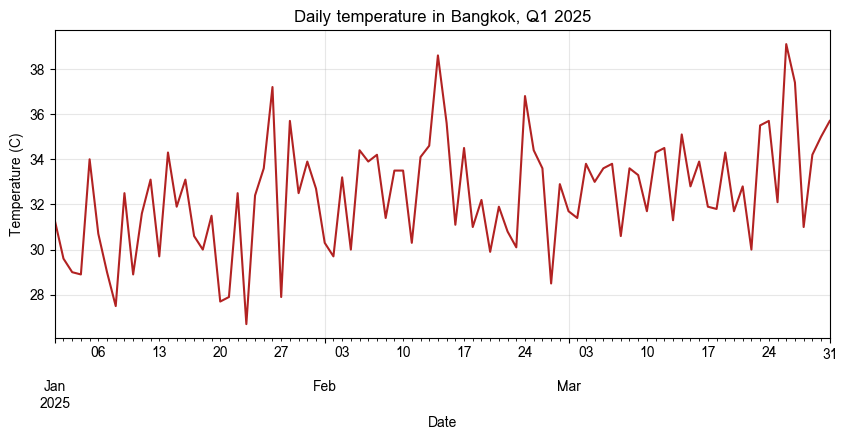

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

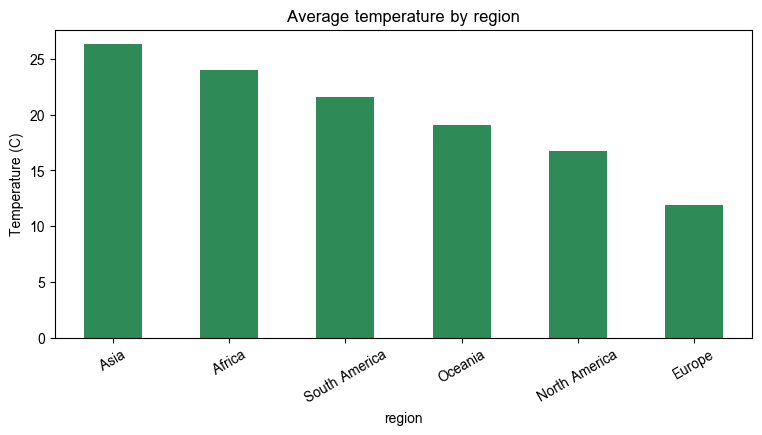

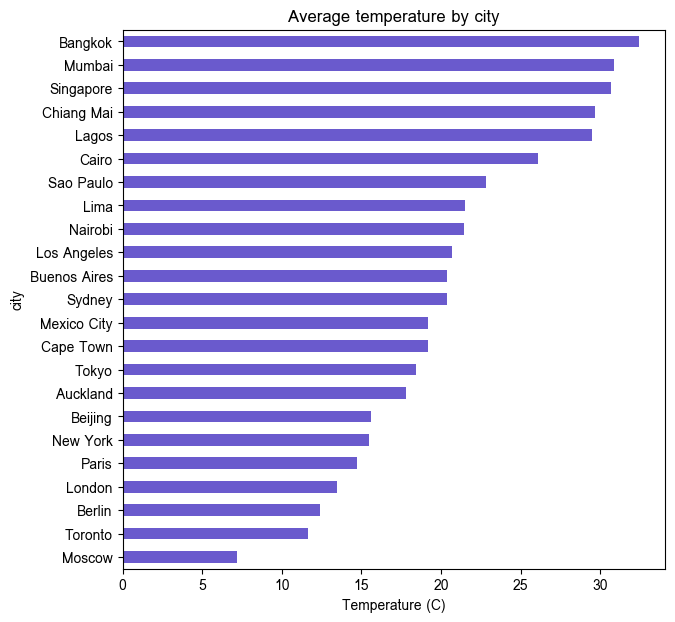

In [99]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

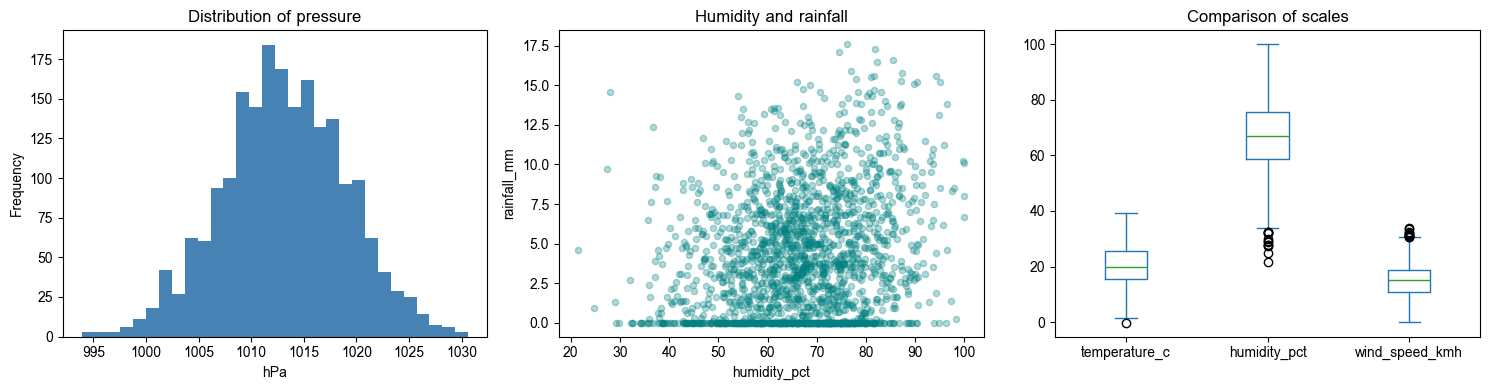

In [100]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

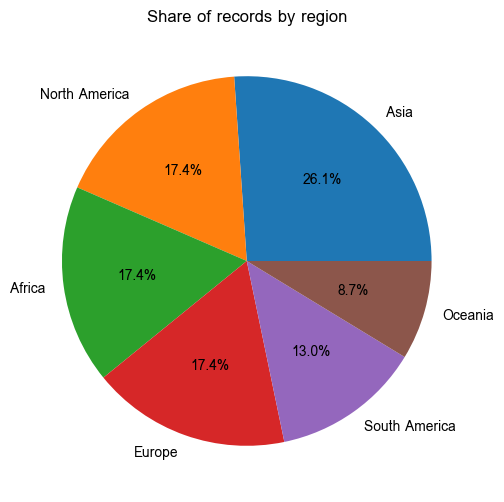

In [101]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

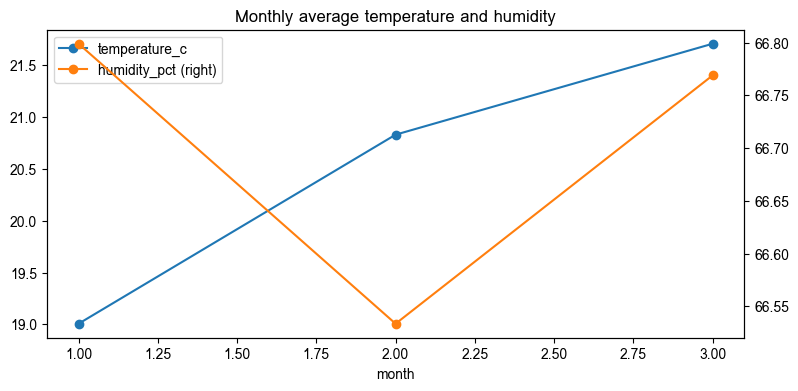

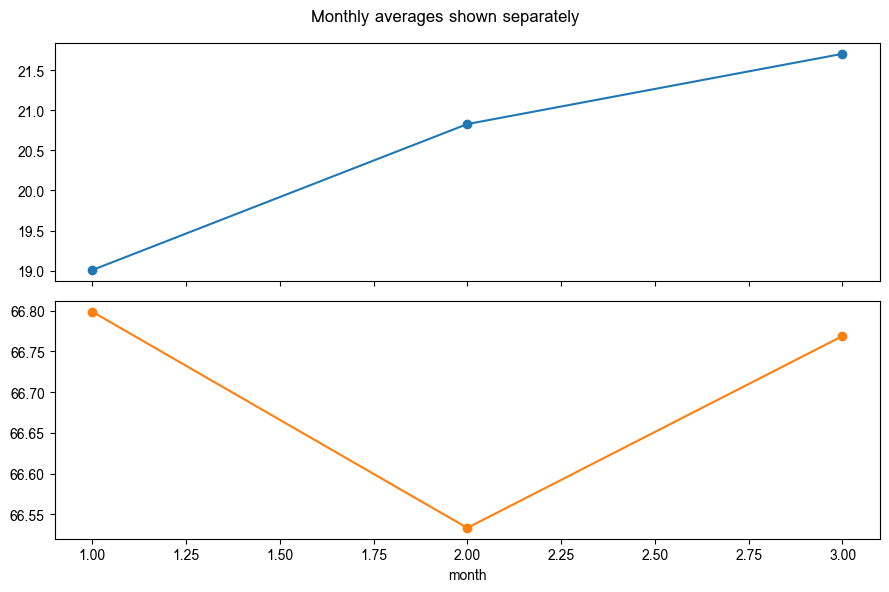

In [102]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

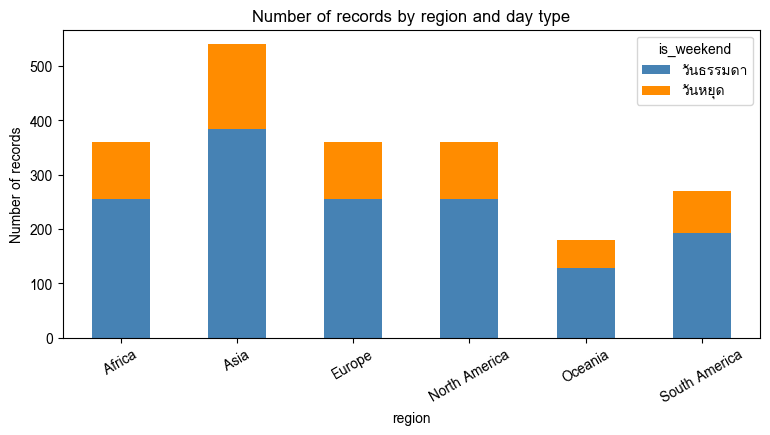

In [103]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

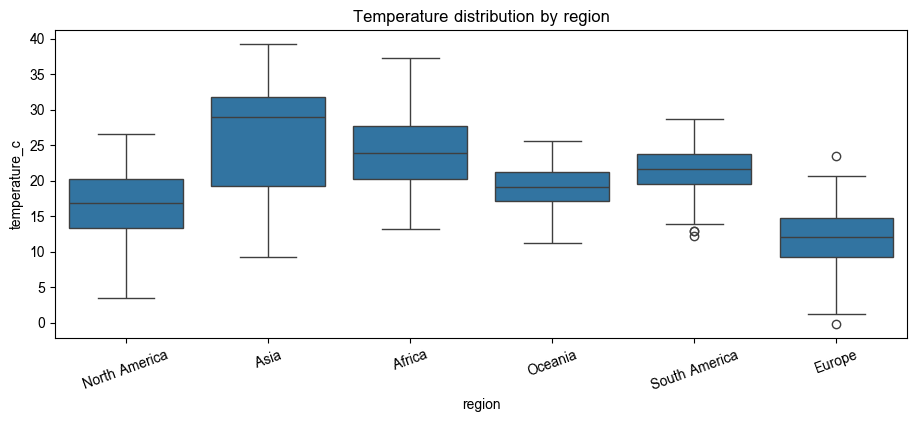

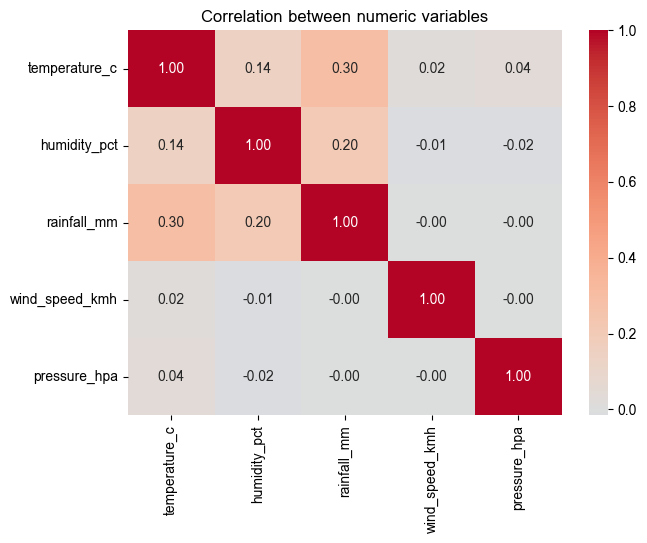

In [104]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

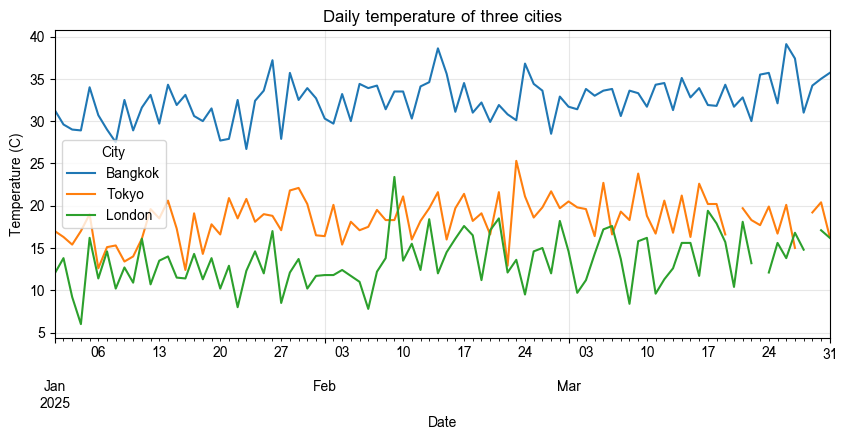

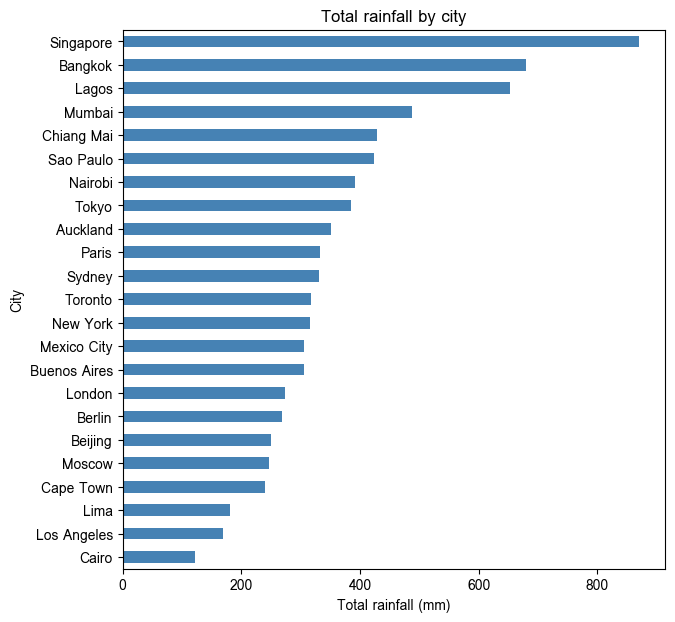

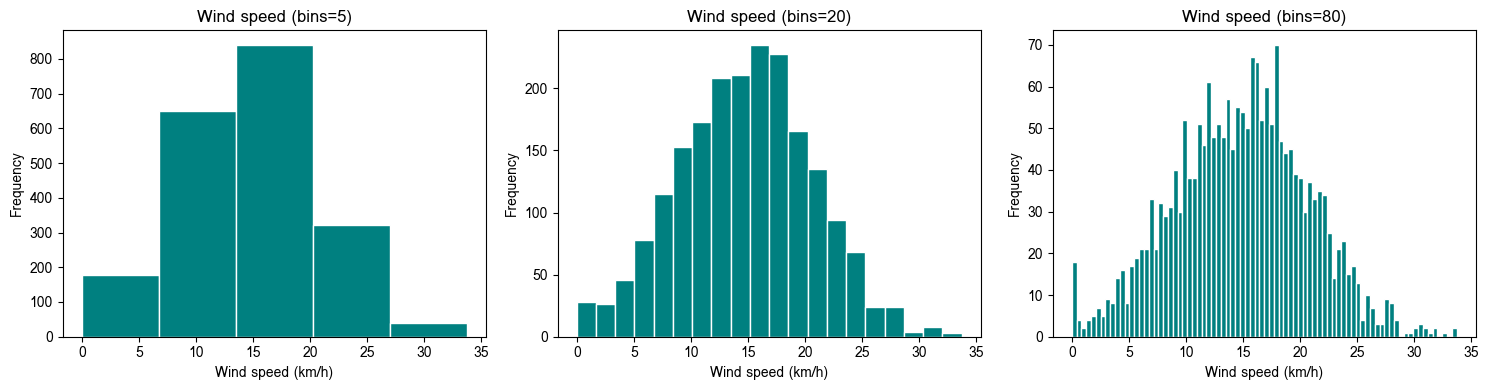

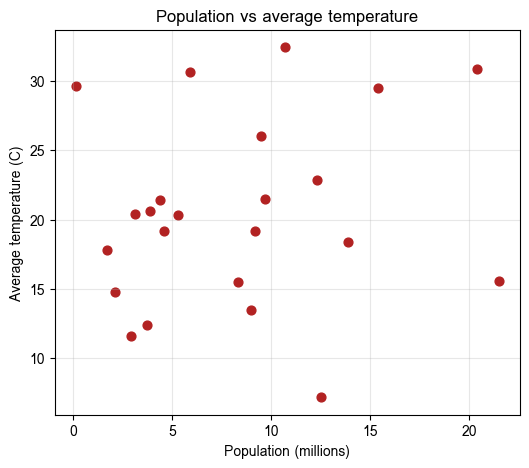

In [105]:
# คำตอบข้อ 17.1
# นิยามฟังก์ชันวาดกราฟแต่ละแบบที่รับ ax เพื่อใช้ซ้ำในข้อ 17.2
cities3 = ["Bangkok", "Tokyo", "London"]

def plot_temp_lines(ax):
    (df.pivot_table(index="date", columns="city", values="temperature_c")[cities3]
       .plot(ax=ax))
    ax.set_title("Daily temperature of three cities")
    ax.set_xlabel("Date"); ax.set_ylabel("Temperature (C)")
    ax.legend(title="City"); ax.grid(alpha=0.3)

def plot_rain_barh(ax):
    (df.groupby("city")["rainfall_mm"].sum().sort_values()      # เรียงน้อยไปมาก เพราะ barh วาดจากล่างขึ้นบน -> มากที่สุดอยู่บนสุด
       .plot(kind="barh", ax=ax, color="steelblue"))
    ax.set_title("Total rainfall by city")
    ax.set_xlabel("Total rainfall (mm)"); ax.set_ylabel("City")

def plot_wind_hist(ax, bins=20):
    df["wind_speed_kmh"].plot(kind="hist", bins=bins, ax=ax, color="teal", edgecolor="white")
    ax.set_title(f"Wind speed (bins={bins})")
    ax.set_xlabel("Wind speed (km/h)"); ax.set_ylabel("Frequency")

city_scatter = full.groupby("city").agg(population_millions=("population_millions", "first"),
                                        avg_temp=("temperature_c", "mean"))
def plot_pop_scatter(ax):
    city_scatter.plot(kind="scatter", x="population_millions", y="avg_temp", ax=ax, color="firebrick", s=40)
    ax.set_title("Population vs average temperature")
    ax.set_xlabel("Population (millions)"); ax.set_ylabel("Average temperature (C)")
    ax.grid(alpha=0.3)

# 1) กราฟเส้น
fig, ax = plt.subplots(figsize=(10, 4)); plot_temp_lines(ax); plt.show()

# 2) กราฟแท่งแนวนอน
fig, ax = plt.subplots(figsize=(7, 7)); plot_rain_barh(ax); plt.show()

# 3) ฮิสโตแกรม ลอง bins สามค่า
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, b in zip(axes, [5, 20, 80]):
    plot_wind_hist(ax, bins=b)
plt.tight_layout(); plt.show()

# 4) กราฟจุด
fig, ax = plt.subplots(figsize=(6, 5)); plot_pop_scatter(ax); plt.show()

**คำตอบข้อ 17.1 ข้อ 3 (ผลของการเลือก `bins`):**

`bins` เป็นตัวกำหนดความละเอียดของฮิสโตแกรม ถ้าน้อยเกินไป (เช่น 5) แท่งกว้างจนรูปร่างการกระจายถูกทำให้เรียบเกิน มองไม่เห็นรายละเอียด เช่น ความไม่สมมาตรหรือหลายยอด ถ้ามากเกินไป (เช่น 80) แต่ละแท่งมีข้อมูลน้อยจนกราฟขรุขระและแกว่งตามสัญญาณรบกวน (ข้อมูลมีความละเอียดทศนิยม 1 ตำแหน่ง จึงเห็นแท่งว่างสลับกับแท่งสูง) ค่าปานกลาง (เช่น 20) ให้ภาพรวมที่อ่านได้ดีที่สุด ควรทดลองหลายค่าก่อนสรุปเสมอ

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

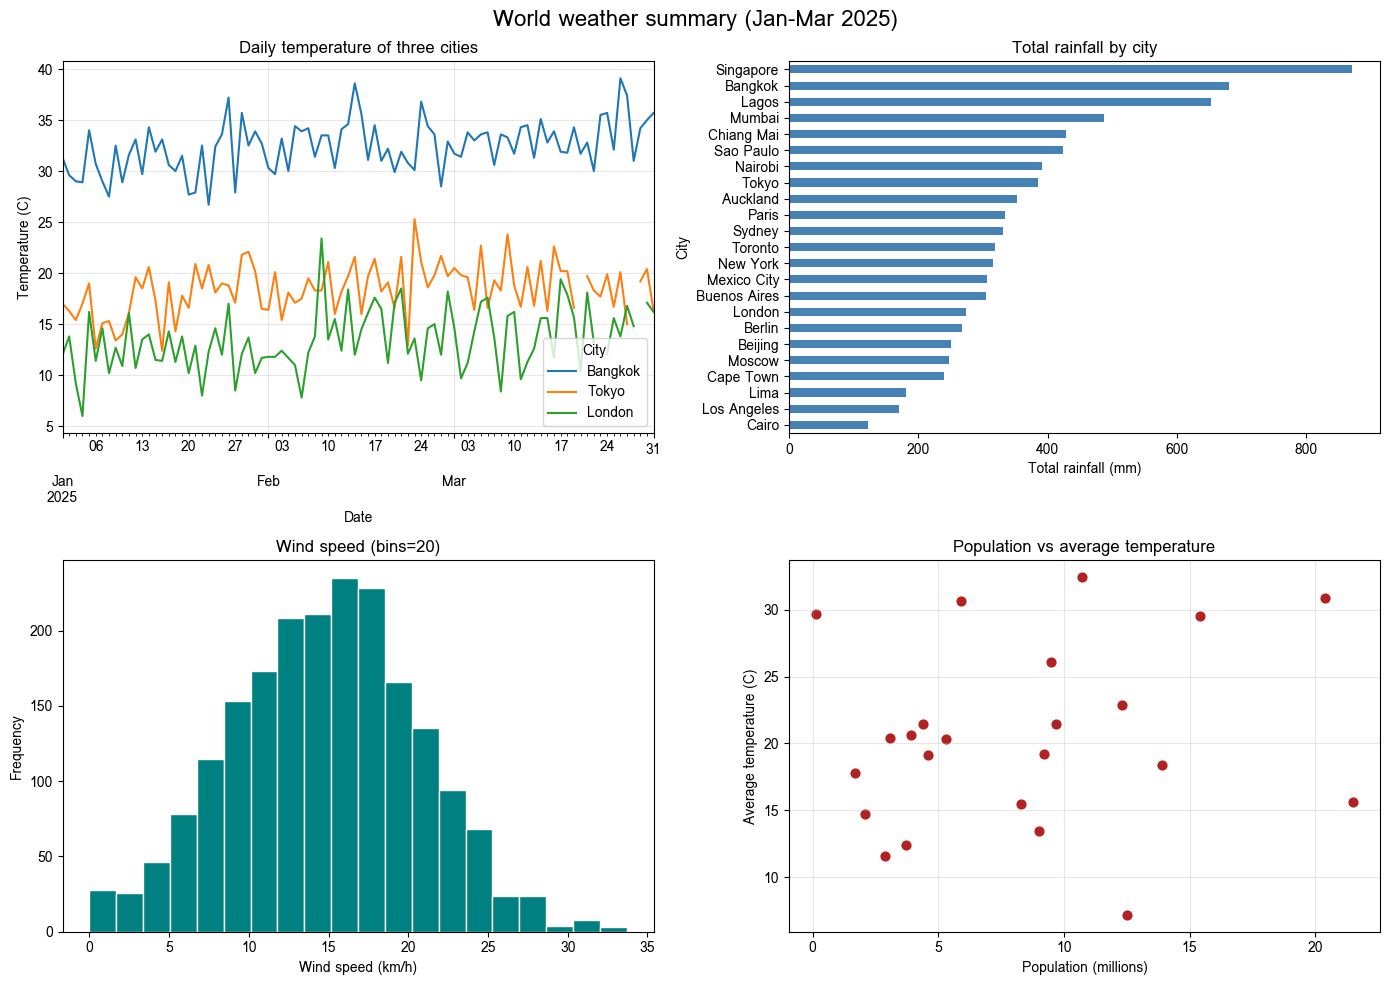

In [106]:
# คำตอบข้อ 17.2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_temp_lines(axes[0, 0])
plot_rain_barh(axes[0, 1])
plot_wind_hist(axes[1, 0], bins=20)
plot_pop_scatter(axes[1, 1])
plt.suptitle("World weather summary (Jan-Mar 2025)", fontsize=16)
plt.tight_layout()
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

region       Africa  Asia  Europe  North America  Oceania  South America
rainfall_mm                                                             
0-2             141   115     158            162       66            121
2-5              89   118     104             91       37             69
5-10             88   203      73             84       60             52
10-20            31    90      15             11        9             21


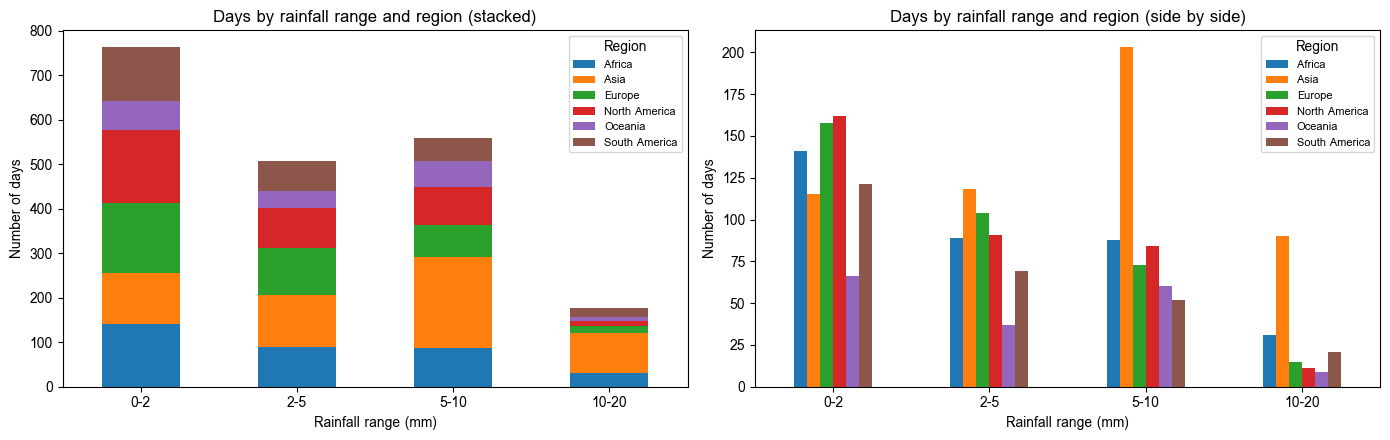

In [107]:
# คำตอบข้อ 17.3
rain_bin = pd.cut(df["rainfall_mm"], bins=[0, 2, 5, 10, 20], include_lowest=True,
                  labels=["0-2", "2-5", "5-10", "10-20"])
rain_ct = pd.crosstab(rain_bin, df["region"])
print(rain_ct)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rain_ct.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Days by rainfall range and region (stacked)")
axes[1].set_title("Days by rainfall range and region (side by side)")
rain_ct.plot(kind="bar", stacked=False, ax=axes[1])
for ax in axes:
    ax.set_xlabel("Rainfall range (mm)"); ax.set_ylabel("Number of days")
    ax.tick_params(axis="x", rotation=0); ax.legend(title="Region", fontsize=8)
plt.tight_layout(); plt.show()

**คำตอบข้อ 17.3 (อธิบาย):**

**กราฟแท่งซ้อน** เหมาะเมื่อสนใจ **ยอดรวม** ของแต่ละช่วงและ **องค์ประกอบ** ว่าแต่ละภูมิภาคเป็นสัดส่วนเท่าใดของยอดรวม (เช่น ช่วงฝนใดมีจำนวนวันมากที่สุด และภูมิภาคใดมีส่วนร่วมมาก) แต่เปรียบเทียบค่าของแต่ละภูมิภาคในช่วงเดียวกันได้ยาก เพราะแท่งแต่ละสีไม่ได้เริ่มจากฐานเดียวกัน (ยกเว้นสีล่างสุด) ส่วน **กราฟแท่งเรียงข้างกัน** เหมาะเมื่อต้องการ **เปรียบเทียบค่าระหว่างภูมิภาค** ในแต่ละช่วงได้ตรง ๆ เพราะทุกแท่งเริ่มจากศูนย์ แต่ดูยอดรวมของแต่ละช่วงไม่สะดวกและใช้พื้นที่มากเมื่อมีหมวดหมู่จำนวนมาก

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

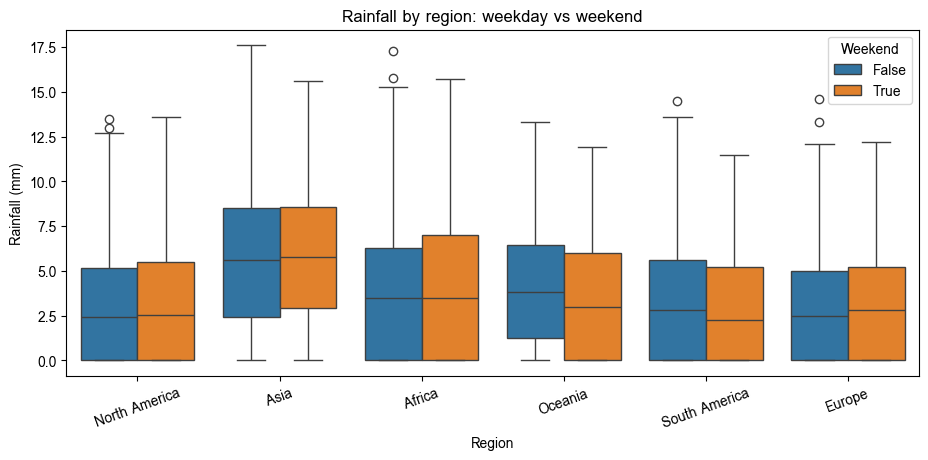

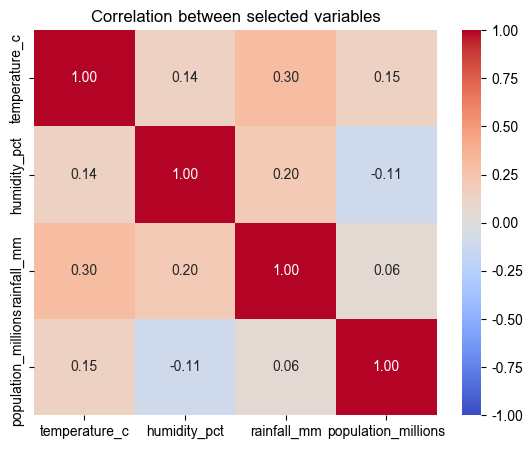

คู่ตัวแปรที่สหสัมพันธ์สูงสุด 3 อันดับ (ตามค่าสัมบูรณ์):
temperature_c  rainfall_mm            0.297
humidity_pct   rainfall_mm            0.204
temperature_c  population_millions    0.146
dtype: float64

มัธยฐานปริมาณฝน วันธรรมดา vs วันหยุด:
is_weekend     False  True 
region                     
Africa           3.5   3.50
Asia             5.6   5.80
Europe           2.5   2.80
North America    2.4   2.55
Oceania          3.8   3.00
South America    2.8   2.25


In [108]:
# คำตอบข้อ 17.4
import seaborn as sns

# กราฟที่ 1: boxplot ของ rainfall_mm จำแนกตามภูมิภาค แยกสีตามวันหยุดสุดสัปดาห์
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=df, x="region", y="rainfall_mm", hue="is_weekend", ax=ax)
ax.set_title("Rainfall by region: weekday vs weekend")
ax.set_xlabel("Region"); ax.set_ylabel("Rainfall (mm)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Weekend")
plt.show()

# กราฟที่ 2: heatmap สหสัมพันธ์ (population_millions มาจากตาราง city_info ที่รวมแล้ว)
corr_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "population_millions"]
corr = full[corr_cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between selected variables")
plt.show()

# ตัวเลขที่ใช้ตีความ
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=np.abs, ascending=False)
print("คู่ตัวแปรที่สหสัมพันธ์สูงสุด 3 อันดับ (ตามค่าสัมบูรณ์):")
print(pairs.head(3).round(3))
wk = df.groupby(["region", "is_weekend"])["rainfall_mm"].median().unstack()
print("\nมัธยฐานปริมาณฝน วันธรรมดา vs วันหยุด:")
print(wk.round(2))

**การตีความข้อ 17.4:**

- **Boxplot:** ปริมาณฝนของแต่ละภูมิภาคมีการกระจายต่างกัน (เช่น เอเชียมีมัธยฐานและค่าสูงสุดมากกว่าภูมิภาคอื่น) แต่ในแต่ละภูมิภาค กล่องของวันธรรมดาและวันหยุดสุดสัปดาห์ซ้อนทับกันเกือบทั้งหมด มัธยฐานต่างกันเพียงเล็กน้อยและไม่คงเส้นคงวา (ภูมิภาคหนึ่งวันหยุดสูงกว่า อีกภูมิภาคหนึ่งต่ำกว่า) จึงไม่มีหลักฐานว่าฝนตกต่างกันระหว่างวันธรรมดาและวันหยุด ซึ่งสมเหตุสมผลเพราะปริมาณฝนเป็นปรากฏการณ์ธรรมชาติที่ไม่ขึ้นกับปฏิทินการทำงานของมนุษย์
- **Heatmap:** ความสัมพันธ์ระหว่างตัวแปรทั้งหมดอยู่ในระดับอ่อน (ค่าสัมบูรณ์ไม่เกินประมาณ 0.3 ตามตัวเลขที่พิมพ์ด้านบน) คู่ที่สูงที่สุดคืออุณหภูมิกับปริมาณฝน (บวกเล็กน้อย เพราะเมืองเขตร้อนอย่าง Singapore, Bangkok และ Lagos ทั้งร้อนและฝนมาก) และความชื้นกับปริมาณฝน ส่วน `population_millions` แทบไม่สัมพันธ์กับตัวแปรอื่น ควรระวังว่า `population_millions` เป็นค่าคงที่ต่อเมือง (ซ้ำกันทุกวันของเมืองนั้น) และมีเพียง 23 เมือง การตีความสหสัมพันธ์จึงมีความน่าเชื่อถือจำกัด และสหสัมพันธ์ไม่ได้บ่งบอกเหตุและผล (causation)

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

**ตารางที่ใช้ในข้อ 18 (`final`)** คือ `full` จากข้อ 14.1 ที่รวมข้อมูลสภาพอากาศ ข้อมูลเมือง และข้อมูลภูมิภาคแล้ว และผ่านการทำความสะอาดตามลำดับดังนี้ (ระบุตามข้อกำหนด)

1. ขจัดแถวซ้ำทั้งแถว (เหลือ 2,070 แถว = 23 เมือง x 90 วัน)
2. ทำชื่อประเทศให้เป็นรูปแบบเดียวกันด้วย `normalize_country`
3. `temperature_c` ที่อยู่นอกช่วง -60 ถึง 60, `humidity_pct` ที่อยู่นอกช่วง 0 ถึง 100 และ `wind_speed_kmh` ที่ติดลบ ถูกแทนด้วยค่าว่าง
4. **ไม่เติมค่าว่าง** ค่าสถิติทุกตัวคำนวณจากค่าที่มี (ข้ามค่าว่าง) เพื่อไม่ให้ค่าที่สร้างขึ้นเองมาบิดผลการวิเคราะห์

In [109]:
final = full.copy()
print(final.shape, "| แถวซ้ำ (city, date):", final.duplicated(["city", "date"]).sum(),
      "| ค่าว่างของอุณหภูมิ:", final["temperature_c"].isna().sum())

(2070, 27) | แถวซ้ำ (city, date): 0 | ค่าว่างของอุณหภูมิ: 25


1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

In [110]:
# คำตอบข้อ 18.1
q1 = final[final["date"].dt.quarter == 1]                                   # ไตรมาสแรก

# ส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวันของแต่ละภูมิภาค (รวมทุกเมืองและทุกวันในภูมิภาค)
region_std = q1.groupby("region")["temperature_c"].std().rename("region_std")

# ส่วนเบี่ยงเบนมาตรฐานของแต่ละเมืองเอง (วัดความแปรปรวนภายในเมือง ไม่รวมความต่างของภูมิอากาศระหว่างเมือง)
city_std = q1.groupby(["region", "city"])["temperature_c"].std().rename("city_std").reset_index()

by_region = city_std.groupby("region").agg(
    mean_city_std=("city_std", "mean"),
    max_city_std=("city_std", "max"),
    city_with_max=("city_std", lambda s: city_std.loc[s.idxmax(), "city"]),
)
by_region["max / mean"] = by_region["max_city_std"] / by_region["mean_city_std"]
table_18_1 = region_std.to_frame().join(by_region).sort_values("region_std", ascending=False).round(2)
display(table_18_1)

top_region = table_18_1.index[0]
print(f"ภูมิภาคที่ส่วนเบี่ยงเบนมาตรฐานสูงสุด: {top_region} ({table_18_1.loc[top_region, 'region_std']} C)")

# ในภูมิภาคนั้น: std ภายในแต่ละเมือง เทียบกับอุณหภูมิเฉลี่ยของแต่ละเมือง
detail = (q1[q1["region"] == top_region].groupby("city")["temperature_c"]
            .agg(mean_temp="mean", city_std="std").sort_values("mean_temp", ascending=False).round(2))
print(f"\nภายใน {top_region}: อุณหภูมิเฉลี่ยของเมืองต่างกันถึง {detail['mean_temp'].max() - detail['mean_temp'].min():.1f} C "
      f"แต่ std ภายในเมืองอยู่ระหว่าง {detail['city_std'].min():.2f} ถึง {detail['city_std'].max():.2f} C")
print(detail)

,region_std,mean_city_std,max_city_std,city_with_max,max / mean
region,,,,,
Asia,7.16,2.67,2.87,Beijing,1.08
Africa,4.88,2.79,2.85,Nairobi,1.02
North America,4.52,2.87,3.02,New York,1.05
Europe,4.07,2.88,3.03,Paris,1.05
Oceania,3.08,2.81,2.82,Sydney,1.00
South America,3.06,2.89,3.11,Lima,1.08


ภูมิภาคที่ส่วนเบี่ยงเบนมาตรฐานสูงสุด: Asia (7.16 C)

ภายใน Asia: อุณหภูมิเฉลี่ยของเมืองต่างกันถึง 16.8 C แต่ std ภายในเมืองอยู่ระหว่าง 2.49 ถึง 2.87 C
            mean_temp  city_std
city                           
Bangkok         32.44      2.49
Mumbai          30.87      2.54
Singapore       30.64      2.71
Chiang Mai      29.65      2.86
Tokyo           18.41      2.52
Beijing         15.60      2.87


**ข้อสรุปข้อ 18.1:** ภูมิภาคที่มีส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวันสูงที่สุดในไตรมาสแรกคือ **เอเชีย** (ประมาณ 7.2 องศา สูงกว่าภูมิภาคอื่นชัดเจน) และความแปรปรวนนี้ **ไม่ได้เกิดจากเมืองใดเมืองหนึ่งเป็นหลัก** เพราะ std ภายในแต่ละเมืองของเอเชียใกล้เคียงกันหมด (ประมาณ 2.5-2.9 องศา และอัตราส่วน `max / mean` ใกล้ 1) แต่เกิดจาก **ความต่างของระดับอุณหภูมิเฉลี่ยระหว่างเมือง** ในภูมิภาคเดียวกัน (เมืองเขตร้อนอย่าง Singapore, Bangkok และ Mumbai ประมาณ 30 องศา เทียบกับ Beijing และ Tokyo ประมาณ 15-18 องศา) เมื่อรวมทุกเมืองเข้าด้วยกัน std ของทั้งภูมิภาคจึงสูงกว่า std ภายในเมืองราว 2.5 เท่า ส่วนภูมิภาคอื่นมีเมืองที่ภูมิอากาศใกล้กันกว่า std รวมจึงต่ำกว่า วิธีจัดการค่าผิดปกติ: ค่านอกช่วง -60 ถึง 60 ถูกแทนด้วยค่าว่างและไม่เติมค่า

2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

In [111]:
# คำตอบข้อ 18.2
heavy = final["rainfall_mm"] > 10
tbl = pd.DataFrame({
    "heavy_days": heavy.groupby(final["city"]).sum(),
    "n_valid_days": final.groupby("city")["rainfall_mm"].count(),
})
tbl["heavy_share_pct"] = (tbl["heavy_days"] / tbl["n_valid_days"] * 100).round(2)

by_share = tbl.nlargest(5, "heavy_share_pct")
by_days = tbl.nlargest(5, "heavy_days")

table_18_2 = pd.concat({"เรียงตามสัดส่วน": by_share.reset_index(), "เรียงตามจำนวนวัน": by_days.reset_index()}, axis=1)
display(table_18_2)

print("ลำดับเมืองตามสัดส่วน:", by_share.index.tolist())
print("ลำดับเมืองตามจำนวนวัน:", by_days.index.tolist())
print("ต่างกันหรือไม่:", by_share.index.tolist() != by_days.index.tolist())

เรียงตามสัดส่วน                                         เรียงตามจำนวนวัน  \
             city heavy_days n_valid_days heavy_share_pct             city   
0       Singapore         44           90           48.89        Singapore   
1         Bangkok         23           87           26.44          Bangkok   
2           Lagos         22           88           25.00            Lagos   
3       Sao Paulo         11           88           12.50        Sao Paulo   
4      Chiang Mai          9           85           10.59     Buenos Aires   

                                           
  heavy_days n_valid_days heavy_share_pct  
0         44           90           48.89  
1         23           87           26.44  
2         22           88           25.00  
3         11           88           12.50  
4          9           88           10.23

ลำดับเมืองตามสัดส่วน: ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Chiang Mai']
ลำดับเมืองตามจำนวนวัน: ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Buenos Aires']
ต่างกันหรือไม่: True


**ข้อสรุปข้อ 18.2:** ตัวชี้วัดสองแบบให้ผลใกล้เคียงกัน 4 อันดับแรกเป็นเมืองเดียวกันคือ Singapore, Bangkok, Lagos และ Sao Paulo (Singapore มีฝนตกหนักเกือบครึ่งหนึ่งของวัน) แต่ **อันดับที่ 5 ต่างกัน** คือ Chiang Mai (เมื่อวัดด้วยสัดส่วน) กับ Buenos Aires (เมื่อวัดด้วยจำนวนวัน)

สาเหตุที่ให้ผลต่างกันคือจำนวนวันที่มีข้อมูลฝน (`n_valid_days`) ของแต่ละเมืองไม่เท่ากัน เพราะบางเมืองมีค่าปริมาณฝนว่าง (ซึ่งไม่ได้เติมค่า) ทั้งสองเมืองมีวันฝนตกหนัก 9 วันเท่ากัน แต่ Chiang Mai มีข้อมูลฝนเพียง 85 วัน ส่วน Buenos Aires มี 88 วัน สัดส่วนของ Chiang Mai จึงสูงกว่า ตัวชี้วัดแบบสัดส่วนหารด้วยจำนวนวันที่มีข้อมูลของเมืองนั้น จึงปรับผลกระทบจากข้อมูลไม่ครบแล้ว และเปรียบเทียบข้ามเมืองได้เป็นธรรมกว่า (วิธีจัดการค่าว่าง: ไม่เติมค่า ใช้เฉพาะวันที่มีข้อมูลเป็นตัวหาร)

3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

In [112]:
# คำตอบข้อ 18.3
# ระดับเมือง (23 เมือง): ใช้ฝนเฉลี่ยรายวันแทนฝนรวม เพื่อไม่ให้ผลถูกบิดเพราะจำนวนวันที่มีข้อมูลต่างกัน
city_level = final.groupby("city").agg(
    population_millions=("population_millions", "first"),
    avg_temp=("temperature_c", "mean"),
    avg_daily_rain=("rainfall_mm", "mean"),
)

corr_18_3 = pd.DataFrame({
    "pearson": city_level.corr(method="pearson")["population_millions"],
    "spearman": city_level.corr(method="spearman")["population_millions"],
}).drop(index="population_millions").round(3)
display(corr_18_3)
print("จำนวนเมืองที่ใช้คำนวณ:", len(city_level))

,pearson,spearman
avg_temp,0.159,0.230
avg_daily_rain,0.123,0.057


จำนวนเมืองที่ใช้คำนวณ: 23


**ข้อสรุปข้อ 18.3:** ค่าสหสัมพันธ์ระหว่างจำนวนประชากรของเมืองกับอุณหภูมิเฉลี่ยและปริมาณฝนเฉลี่ยรายวันมีค่าต่ำมาก (ประมาณ 0.06 ถึง 0.23 ทั้ง Pearson และ Spearman ตามตารางด้านบน) จึง **ไม่พบความสัมพันธ์ที่ชัดเจน** ระหว่างจำนวนประชากรกับสภาพอากาศของเมืองในข้อมูลชุดนี้ (ทิศทางเป็นบวกเล็กน้อย แต่ด้วยจำนวนเมืองเพียง 23 เมือง ค่าระดับนี้ไม่แตกต่างจากศูนย์อย่างมีนัยสำคัญ)

**ข้อควรระวังในการตีความ:** (1) มีเพียง 23 เมือง ซึ่งเป็นตัวอย่างขนาดเล็กและไม่ได้สุ่มมา ค่าสหสัมพันธ์จึงเปลี่ยนได้มากหากเพิ่มหรือตัดเมืองเพียงเมืองเดียว (2) จำนวนประชากรเบ้มาก (มีเมืองขนาดใหญ่ไม่กี่เมือง) จึงควรดู Spearman ควบคู่กับ Pearson (3) ข้อมูลครอบคลุมเพียง 3 เดือน (ม.ค.-มี.ค.) ซึ่งเป็นคนละฤดูของแต่ละซีกโลก และ (4) สหสัมพันธ์ไม่ใช่ความเป็นเหตุเป็นผล อุณหภูมิและฝนของเมืองขึ้นกับละติจูด ภูมิประเทศ และใกล้ทะเลมากกว่าจำนวนประชากร

4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

In [113]:
# คำตอบข้อ 18.4
# เกณฑ์ตัดสินใจ: "วันที่ไม่เหมาะกับการเดินทาง" คือวันที่เข้าเงื่อนไขอย่างน้อยหนึ่งข้อ
#   (1) ฝนตกหนัก : rainfall_mm > 10
#   (2) ร้อนจัดและชื้น : อุณหภูมิที่รู้สึก (heat_index จากข้อ 16.3) >= 38
#   (3) หนาวจัด : temperature_c <= 0
# เดือนที่ควรหลีกเลี่ยงของแต่ละภูมิภาค = เดือนที่สัดส่วนวันที่ไม่เหมาะสมสูงสุด
d = final.assign(
    hi=heat_index(final["temperature_c"], final["humidity_pct"]),
)
d["bad_day"] = (d["rainfall_mm"] > 10) | (d["hi"] >= 38) | (d["temperature_c"] <= 0)

bad_share = (d.groupby(["region", "month"])["bad_day"].mean() * 100).unstack().round(1)
bad_share["worst_month"] = bad_share.idxmax(axis=1)
bad_share["worst_share_pct"] = bad_share.drop(columns="worst_month").max(axis=1)
display(bad_share)

# เหตุผลของสัดส่วนที่เกิดจากแต่ละเงื่อนไข ในเดือนที่แย่ที่สุด
reasons = (d.assign(heavy_rain=d["rainfall_mm"] > 10, too_hot=d["hi"] >= 38, freezing=d["temperature_c"] <= 0)
             .groupby(["region", "month"])[["heavy_rain", "too_hot", "freezing"]].mean().mul(100).round(1))
worst = reasons.loc[list(bad_share["worst_month"].items())]
print("สัดส่วนของแต่ละเงื่อนไข (%) ในเดือนที่ควรหลีกเลี่ยงที่สุดของแต่ละภูมิภาค")
display(worst)

month,1,2,3,worst_month,worst_share_pct
region,,,,,
Africa,11.3,16.1,19.4,3,19.4
Asia,29.0,47.6,43.5,2,47.6
Europe,4.0,3.6,5.6,3,5.6
North America,3.2,3.6,2.4,2,3.6
Oceania,1.6,3.6,9.7,3,9.7
South America,8.6,8.3,6.5,1,8.6


สัดส่วนของแต่ละเงื่อนไข (%) ในเดือนที่ควรหลีกเลี่ยงที่สุดของแต่ละภูมิภาค


,,heavy_rain,too_hot,freezing
region,month,,,
Africa,3,8.1,14.5,0.0
Asia,2,22.6,32.7,0.0
Europe,3,5.6,0.0,0.0
North America,2,3.6,0.0,0.0
Oceania,3,9.7,0.0,0.0
South America,1,8.6,0.0,0.0


**ข้อสรุปข้อ 18.4:** เดือนที่ควรหลีกเลี่ยงของแต่ละภูมิภาคคือคอลัมน์ `worst_month` ในตารางด้านบน

**เหตุผลของเกณฑ์:** เลือกวัดจาก "สัดส่วนของวันที่ไม่เหมาะสม" เพราะเข้าใจง่ายและเปรียบเทียบข้ามเดือนได้ตรง ๆ โดยรวมความเสี่ยงหลักสามอย่างที่กระทบการเดินทางจริง และวัดได้จากข้อมูลที่มี ได้แก่ ฝนตกหนัก (> 10 mm ตรงกับเกณฑ์ที่ใช้ในข้อ 12) ความร้อนชื้นที่ทำให้รู้สึกร้อนจัด (ใช้ `heat_index` จากข้อ 16.3 ไม่ใช้อุณหภูมิอย่างเดียว เพราะความชื้นมีผลต่อความสบาย) และอากาศหนาวจัด (<= 0 องศา) ตารางที่สองแสดงว่าในเดือนที่แย่ที่สุดของแต่ละภูมิภาค ปัจจัยใดเป็นสาเหตุหลัก (เช่น เอเชียเดือนกุมภาพันธ์เสี่ยงทั้งความร้อนชื้นและฝนหนัก ส่วนยุโรปและอเมริกาเหนือมีวันไม่เหมาะสมน้อยมากทุกเดือน)

**ข้อจำกัด:** ข้อมูลมีเพียง 3 เดือน (ม.ค.-มี.ค.) จึงเปรียบเทียบได้เฉพาะสามเดือนนี้ ไม่ใช่ทั้งปี และเกณฑ์ (10 mm, 38 และ 0 องศา) เป็นการกำหนดเองที่ปรับได้ตามวัตถุประสงค์ วิธีจัดการค่าว่าง: วันที่ข้อมูลว่างไม่ถูกนับเป็นวันที่ไม่เหมาะสม (เงื่อนไขที่มีค่าว่างให้ผลเป็นเท็จ)

---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️